# España: revisión de las diferencias con el Excel

**Corte: 20/10/2026.** Se conservan para diagnóstico las 26 series de código compatible con diferencias, las tres de unidades y las dos de discrepancias numéricas: **31 series españolas**. Las diez con cambio de base se aceptan por decisión del alumno usando íntegramente la edición AMECO actual. Los cuatro códigos de EE. UU. son referencias auxiliares y no entran en silver de España.

Las 31 series quedaron aceptadas tras la revisión del alumno del 20/10/2026, adoptando los datos publicados vigentes sin afirmar una causa concreta de discrepancia. El notebook no descarga, reescala ni modifica las series. La vista interactiva requiere ejecutar las celdas en un kernel local; el apéndice deja una figura por serie visible también sin kernel.

```sh
uv sync --group analysis --locked
uv run --group analysis jupyter notebook notebooks/02_revision_espana.ipynb
```

Si no tienes la interfaz de Jupyter instalada, abre este archivo en VS Code con el intérprete `.venv/bin/python` o ejecuta `uv run --with notebook --group analysis jupyter notebook notebooks/02_revision_espana.ipynb`.


In [1]:
from pathlib import Path
import sys, json
import polars as pl
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/spain_silver.py').exists())
sys.path.insert(0, str(root / 'src'))
from review_spain import load, summary, annual, show, explorer
from snapshot import verify
verify('v0_2026-10-16')
cat, pending, pairs = load()
print(f"España: {cat.height} entradas de catálogo; {pending.height} series para revisión.")
assert pending.height == 31


España: 99 entradas de catálogo; 31 series para revisión.


## 1. Decisiones vigentes y catálogo

La política está en `datos/catalogo/decisiones_espana.json`. Tras revisar las anotaciones del alumno, hay 84 series AMECO españolas: las 74 explícitas recuperadas y diez localizadas por concepto. Se conservan las decisiones sobre edición vigente y cambios de base. Las 31 comparaciones se conservan como diagnóstico histórico, sin bloquear su inclusión en la vista anual. AMGE/AXGE se excluyen de los objetivos actuales; la fecha exacta de su retirada no se ha acreditado.

No se mezclan bases del Excel y de AMECO en una misma serie. Los años 2026–2027 se conservan como horizonte de previsión en la tabla larga y se excluyen de la vista analítica. Esto no convierte automáticamente los años anteriores en definitivos.


In [2]:
display(cat.group_by('status').len().sort('status'))
display(cat.filter(pl.col('status') == 'ACEPTADA_BASE_EDICION_ACTUAL').select('series_id','name','unit','decision_note'))


status,len
str,u32
"""ACEPTADA_BASE_EDICION_ACTUAL""",10
"""ACEPTADA_COINCIDENCIA_NUMERICA""",33
"""ACEPTADA_CONCEPTO_Y_FUENTE""",20
"""ACEPTADA_FUENTE_INE_ACTUAL""",3
"""ACEPTADA_REVISION_MANUAL""",31
"""EXCLUIDA_NO_PUBLICADA_EDICION_…",2


series_id,name,unit,decision_note
str,str,str,str
"""ESP.1.0.0.0.AVGDK""","""Gross domestic product at 2020…","""capital productivity""","""Se adopta íntegramente la seri…"
"""ESP.1.0.0.0.RKNDE""","""Net capital stock at 2020 pric…","""1000 EURO-ESP""","""Se adopta íntegramente la seri…"
"""ESP.1.0.99.0.OKND""","""Net capital stock at 2020 pric…","""Mrd ECU/EUR""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.APNDK""","""Net returns on net capital sto…","""(2020 = 100)""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.VPRI""","""Industrial production: constru…","""(2020 = 100)""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.ZEKND""","""Capital-labour substitution: t…","""(2020 = 100)""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.ZKNDE""","""Labour-capital substitution: t…","""(2020 = 100)""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.ZVGDE""","""Labour share in total factor p…","""(2020 = 100)""","""Se adopta íntegramente la seri…"
"""ESP.3.0.0.0.ZVGDF""","""Total factor productivity: tot…","""(2020 = 100)""","""Se adopta íntegramente la seri…"


## 2. Lista de revisión

La razón es **AMECO/Excel**, la diferencia relativa se divide por el valor absoluto del Excel y se deja vacía cuando ese valor es cero. El crecimiento solo se calcula entre años consecutivos, con valores positivos. Para cuotas, ratios o series con ceros o negativos, el gráfico muestra cambios en unidades de la serie en lugar de tasas; la MAE de crecimiento queda vacía. Una razón constante puede sugerir una escala; no demuestra su causa. No se aplica ninguna corrección automáticamente.


In [3]:
diagnostics = summary()
display(diagnostics)


series_id,name,status,n,median_ratio,max_absolute_relative_pct,growth_mae_pp,n_changed,review_note
str,str,str,i64,f64,f64,f64,i64,str
"""ESP.1.0.0.0.AKGDV""","""Marginal efficiency of capital…","""ACEPTADA_REVISION_MANUAL""",63,1.009041,150.93409,null,63,"""Revisión visual y de edición p…"
"""ESP.1.0.0.0.AKNDV""","""Net capital stock per unit of …","""ACEPTADA_REVISION_MANUAL""",64,1.020622,4.312162,null,63,"""Revisión visual y de edición p…"
"""ESP.1.0.0.0.AMGT""","""Share of imports of goods in w…","""ACEPTADA_REVISION_MANUAL""",40,1.001173,5.998182,null,40,"""La unidad antigua está vacía. …"
"""ESP.1.0.0.0.AXGT""","""Share of exports of goods in w…","""ACEPTADA_REVISION_MANUAL""",40,1.014026,7.78,null,40,"""La unidad antigua está vacía. …"
"""ESP.1.0.0.0.NETN""","""Employment, persons: total eco…","""ACEPTADA_REVISION_MANUAL""",65,1.0,0.578811,0.009309,3,"""Empleo de contabilidad naciona…"
…,…,…,…,…,…,…,…,…
"""ESP.1.1.0.0.UVG0""","""Gross Value Added at current p…","""ACEPTADA_REVISION_MANUAL""",24,1.008779,4.699065,0.208423,24,"""Revisión visual y de edición p…"
"""ESP.1.1.0.0.UVG1""","""Gross Value Added at current p…","""ACEPTADA_REVISION_MANUAL""",24,0.957427,25.207478,1.23116,24,"""Revisión visual y de edición p…"
"""ESP.1.1.0.0.UVG2""","""Gross value added at current p…","""ACEPTADA_REVISION_MANUAL""",24,0.977673,6.553585,0.434792,24,"""Revisión visual y de edición p…"


## 3. Explorador

El selector permite ver niveles, razón, diferencias relativas y tasas anuales. El factor de escala es una **hipótesis visual** que solo modifica la línea del Excel en el panel de niveles. Los demás paneles mantienen los valores originales. No afecta a silver ni acepta la serie.


### `ESP.1.0.0.0.AKGDV`

Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** K, fila 14

**Unidad Excel:** `Marginal efficiency of capital` · **Unidad actual:** `Marginal efficiency of capital`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)',
 'new_title': 'Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)',
 'n_overlap': 63,
 'equal_values': 0,
 'median_ratio': 1.0090412928930959,
 'max_abs_relative_diff_pct': 150.93409026444297,
 'mean_abs_growth_difference_pp': 1.5547919396379983}

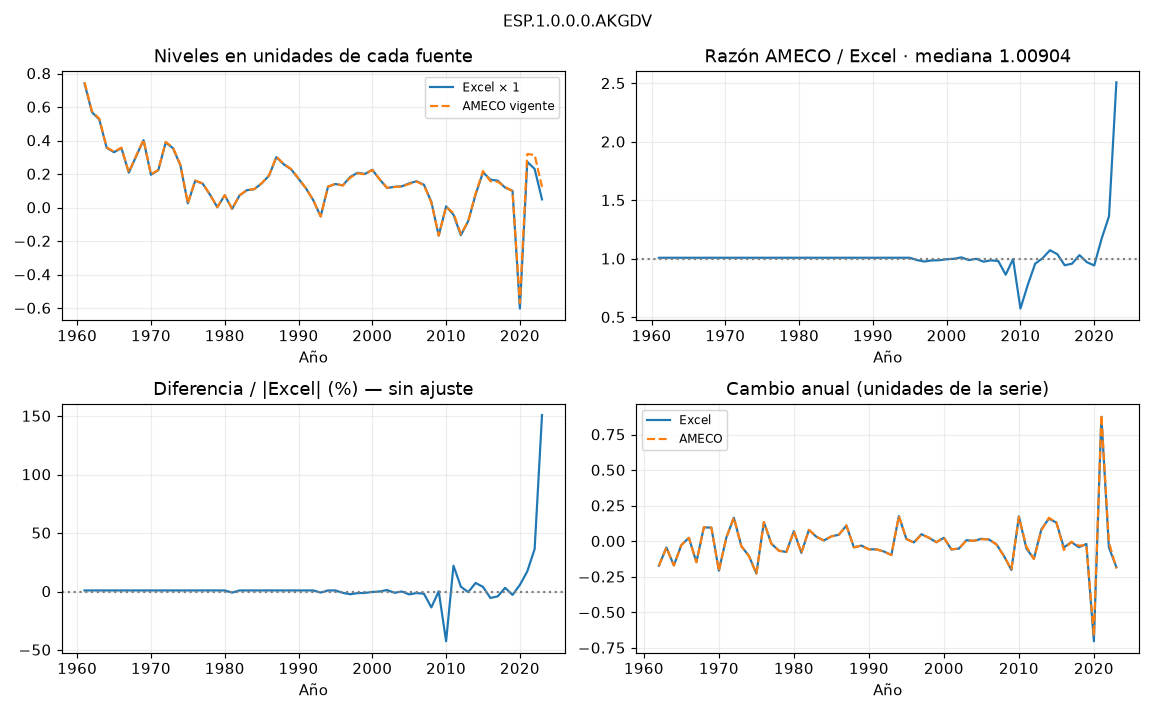

**Diez mayores diferencias absolutas de nivel.** En unidades distintas, se revisa primero la unidad.

code,year,excel,ameco,difference,difference_pct,ratio,equal_with_rounding,growth_excel_pct,growth_ameco_pct,change_excel,change_ameco,growth_diff_pp
str,i64,f64,f64,f64,f64,f64,bool,f64,f64,f64,f64,f64
"""ESP.1.0.0.0.AKGDV""",2022,0.2306858,0.31451,0.083824,36.336957,1.36337,false,-15.503823,-1.703338,-0.042328,-0.00545,13.800486
"""ESP.1.0.0.0.AKGDV""",2023,0.0490049,0.12297,0.0739651,150.93409,2.509341,false,-78.756863,-60.901084,-0.181681,-0.19154,17.855779
"""ESP.1.0.0.0.AKGDV""",2021,0.2730133,0.31996,0.046947,17.195756,1.171958,false,null,null,0.8752817,0.88797,null
"""ESP.1.0.0.0.AKGDV""",2020,-0.602268,-0.56801,0.034258,5.688228,0.943118,false,null,null,-0.702867,-0.66569,null
"""ESP.1.0.0.0.AKGDV""",2011,-0.042283,-0.03293,0.009353,22.119817,0.778802,false,null,null,-0.050184,-0.03747,null
"""ESP.1.0.0.0.AKGDV""",2016,0.1667443,0.15752,-0.009224,-5.532003,0.94468,false,-20.665198,-27.918364,-0.043434,-0.06101,-7.253166
"""ESP.1.0.0.0.AKGDV""",2015,0.210178,0.21853,0.008352,3.973775,1.039738,false,166.884904,158.584783,0.1314257,0.13402,-8.300121
"""ESP.1.0.0.0.AKGDV""",2012,-0.164716,-0.15792,0.006796,4.125657,0.958743,false,null,null,-0.122433,-0.12499,null
"""ESP.1.0.0.0.AKGDV""",1961,0.7409834,0.74769,0.006707,0.905095,1.009051,false,null,null,null,null,null


In [4]:
controls = explorer()


Para inspeccionar por código, sin widgets:

```python
show('ESP.1.0.0.0.URTG', start=1995, end=2025, factor_excel=1e-4)
annual('ESP.1.0.0.0.URTG')  # todas las diferencias y tasas
```

Prioridad de revisión: URTG/UUTG (escala y unidad), UVG4 (niveles), AMGT/AXGT (unidad antigua vacía), después las 26 compatibles. No se atribuyen todas las diferencias a revisiones estadísticas sin evidencia.


## 4. EPA: fila de procedencia desconocida

La anotación literal está en `mercado traballo`, **I29**, junto a una fila rotulada INE/EPA con datos de 1981–2011. No se ha reconstruido la procedencia exacta ni se usa esa fila para producir datos.

Se descargan tres series oficiales de medias de los cuatro trimestres: activos, ocupados y parados, total nacional, ambos sexos, 16 y más años. Tablas INE 65949, 65962 y 65994; identificadores EPA634675/6/7. Los valores están en miles de personas. La tabla actual ofrece **2006–2025**: los años anteriores quedan sin rellenar, no desaparecen del inventario pendiente.

La publicación actual utiliza base poblacional 2011 hasta 2020 y 2021 desde 2021. Es una diferencia metodológica que se conserva por año; no es un cambio de base de precios. EPA, empleo de cuentas nacionales y paro registrado permanecen separados.

Fuentes: [EPA anual](https://www.ine.es/dynt3/inebase/index.htm?capsel=10993&padre=10989), [tabla de parados](https://www.ine.es/jaxiT3/Tabla.htm?t=65994), [metadatos API](https://www.ine.es/dyngs/DAB/index.htm?cid=1102).


In [5]:
labor_comparison = pl.read_csv(root / 'output/revision_espana/epa_comparacion_excel.csv')
display(labor_comparison)
silver = pl.read_parquet(root / 'datos/silver/espana.parquet')
display(silver.filter(pl.col('source').str.starts_with('ine_epa_annual')).group_by(['series_id','population_basis']).agg(pl.col('year').min().alias('first'),pl.col('year').max().alias('last'),pl.len().alias('n')))
epa = silver.filter(pl.col('source').str.starts_with('ine_epa_annual')).pivot(on='series_id',index='year',values='value')
residual = epa.with_columns((pl.col('INE.EPA.ANNUAL.ACTIVOS')-pl.col('INE.EPA.ANNUAL.OCUPADOS')-pl.col('INE.EPA.ANNUAL.PARADOS')).alias('residuo_miles'))
display(residual)
assert residual['residuo_miles'].abs().max() < .11  # cada nivel se publica con un decimal


excel_row,year,excel,ine,difference,unit
i64,i64,f64,f64,f64,str
28,2006,1840.9,1840.9,0.0,"""thousand_persons"""
28,2007,1846.1,1846.1,0.0,"""thousand_persons"""
28,2008,2595.9,2595.9,0.0,"""thousand_persons"""
28,2009,4153.5,4153.5,0.0,"""thousand_persons"""
28,2010,4640.1,4640.1,0.0,"""thousand_persons"""
…,…,…,…,…,…
29,2007,1833.9,1846.1,12.2,"""thousand_persons"""
29,2008,2590.6,2595.9,5.3,"""thousand_persons"""
29,2009,4149.5,4153.5,4.0,"""thousand_persons"""


series_id,population_basis,first,last,n
str,str,i64,i64,u32
"""INE.EPA.ANNUAL.PARADOS""","""2021""",2021,2025,5
"""INE.EPA.ANNUAL.OCUPADOS""","""2011""",2006,2020,15
"""INE.EPA.ANNUAL.ACTIVOS""","""2011""",2006,2020,15
"""INE.EPA.ANNUAL.OCUPADOS""","""2021""",2021,2025,5
"""INE.EPA.ANNUAL.PARADOS""","""2011""",2006,2020,15
"""INE.EPA.ANNUAL.ACTIVOS""","""2021""",2021,2025,5


year,INE.EPA.ANNUAL.ACTIVOS,INE.EPA.ANNUAL.OCUPADOS,INE.EPA.ANNUAL.PARADOS,residuo_miles
i64,f64,f64,f64,f64
2006,21780.0,19939.1,1840.9,1.3642e-12
2007,22426.1,20579.9,1846.1,0.1
2008,23065.6,20469.7,2595.9,-2.2737e-12
2009,23260.4,19106.9,4153.5,0.0
2010,23364.6,18724.5,4640.1,-1.8190e-12
…,…,…,…,…
2021,23309.9,19833.5,3476.4,1.3642e-12
2022,23626.7,20547.5,3079.2,9.0949e-13
2023,24119.7,21182.2,2937.5,0.0


## 5. Estado de silver

`datos/silver/espana.parquet` es la tabla larga de procedencia y valores: conserva las 74 series AMECO recuperadas y las tres nuevas del INE, con estado de aceptación por serie. `espana_anual.parquet` es la vista ancha de las **97 series aceptadas**, sin horizonte de previsión; sus celdas nulas reflejan coberturas distintas. El catálogo es `espana_catalogo.parquet`.

No es todavía toda fila base del Excel: las filas sin código se enumeran en `output/revision_espana/filas_sin_codigo_inventario.csv`. Se conserva ese inventario para evitar que 76 identificadores se confundan con una auditoría completa de producción, demografía, quiebras, dinero u otras referencias no codificadas.


In [6]:
display(silver.group_by(['source','status','apta_analisis']).agg(pl.len().alias('observaciones')))
wide = pl.read_parquet(root / 'datos/silver/espana_anual.parquet')
print('Vista anual:', wide.shape, 'columnas:', wide.columns)
assert not silver.select(pl.struct(['series_id','year']).is_duplicated().any()).item()
assert silver['value'].is_finite().all()


Vista anual: (76, 99) columnas: ['country', 'year', 'ESP.1.0.0.0.AKGDV', 'ESP.1.0.0.0.AKNDV', 'ESP.1.0.0.0.AMGT', 'ESP.1.0.0.0.AVGDK', 'ESP.1.0.0.0.AXGT', 'ESP.1.0.0.0.FETD', 'ESP.1.0.0.0.NETN', 'ESP.1.0.0.0.NLTN', 'ESP.1.0.0.0.NPAN', 'ESP.1.0.0.0.NPCN', 'ESP.1.0.0.0.NPON', 'ESP.1.0.0.0.NPTD', 'ESP.1.0.0.0.NPTN', 'ESP.1.0.0.0.NSTD', 'ESP.1.0.0.0.NUTN', 'ESP.1.0.0.0.OIST', 'ESP.1.0.0.0.OKND', 'ESP.1.0.0.0.RKNDE', 'ESP.1.0.0.0.UCPH', 'ESP.1.0.0.0.UCTG', 'ESP.1.0.0.0.UIGG', 'ESP.1.0.0.0.UIGP', 'ESP.1.0.0.0.UIGT', 'ESP.1.0.0.0.UIST', 'ESP.1.0.0.0.UITT', 'ESP.1.0.0.0.UKCG', 'ESP.1.0.0.0.UKCT', 'ESP.1.0.0.0.UMGS', 'ESP.1.0.0.0.UOGD', 'ESP.1.0.0.0.UQGD', 'ESP.1.0.0.0.URTG', 'ESP.1.0.0.0.USGG', 'ESP.1.0.0.0.USGN', 'ESP.1.0.0.0.USGP', 'ESP.1.0.0.0.UTVT', 'ESP.1.0.0.0.UUTG', 'ESP.1.0.0.0.UVGD', 'ESP.1.0.0.0.UVGM', 'ESP.1.0.0.0.UVGN', 'ESP.1.0.0.0.UVGT', 'ESP.1.0.0.0.UVNN', 'ESP.1.0.0.0.UVNT', 'ESP.1.0.0.0.UWCD', 'ESP.1.0.0.0.UXGS', 'ESP.1.0.0.0.UYGD', 'ESP.1.0.0.0.UYVT', 'ESP.1.0.0.0.ZNAWRU', 'E

source,status,apta_analisis,observaciones
str,str,bool,u32
"""ine_epa_annual_activos""","""ACEPTADA_FUENTE_INE_ACTUAL""",true,20
"""ameco_spring2026""","""ACEPTADA_BASE_EDICION_ACTUAL""",true,675
"""estat_nama_10_gdp""","""ACEPTADA_CONCEPTO_Y_FUENTE""",true,62
"""ine_epa_annual_ocupados""","""ACEPTADA_FUENTE_INE_ACTUAL""",true,20
"""ine_epa_annual_parados""","""ACEPTADA_FUENTE_INE_ACTUAL""",true,20
"""pwt110""","""ACEPTADA_CONCEPTO_Y_FUENTE""",true,148
"""ameco_spring2026""","""ACEPTADA_CONCEPTO_Y_FUENTE""",true,538
"""ameco_spring2026""","""ACEPTADA_COINCIDENCIA_NUMERICA""",true,2167
"""ine_integrated_accounts""","""ACEPTADA_CONCEPTO_Y_FUENTE""",true,180


## 6. Mantener el registro de decisiones

Edita únicamente las decisiones que quieras aceptar. Se adopta el valor publicado actual completo, no el del Excel ni el reescalado diagnóstico. La celda siguiente solo previsualiza; para persistir hay instrucciones explícitas debajo. Puedes mantener el resto pendiente.


In [7]:
# Ejemplo de formato; vacío para añadir decisiones futuras; las 31 aceptaciones actuales ya están en el JSON:
manual_decisions = {
    # 'ESP.1.0.0.0.AMGT': {
    #     'action': 'accept_current_edition',
    #     'note': 'Explicar unidad, denominador y evidencia consultada.'
    # }
}
assert set(manual_decisions) <= set(pending['series_id'])
assert all(v.get('note') and v.get('action') in ['accept_current_edition','keep_pending'] for v in manual_decisions.values())
display(manual_decisions)


{}

Cuando termines, guarda las decisiones en `datos/catalogo/decisiones_espana.json`, campo `manual_decisions`, y ejecuta `uv run python src/spain_silver.py`. O ejecuta expresamente este bloque:

```python
policy_path = root / 'datos/catalogo/decisiones_espana.json'
policy = json.loads(policy_path.read_text())
policy['manual_decisions'].update(manual_decisions)
policy_path.write_text(json.dumps(policy, ensure_ascii=False, indent=2) + '\n')
from spain_silver import build
build()
```

Las 31 series del explorador se mantienen como cohorte de revisión incluso tras aceptar alguna, para conservar su comparación. El estado original de la auditoría permanece en `initial_status`. La tabla de revisión fechada 19/10 es evidencia histórica; el catálogo vigente de España está en `output/revision_espana/catalogo_espana.csv`.

## 7. Apéndice: las 31 comparaciones

Las salidas guardadas permiten revisar todas las figuras sin un kernel. Para datos anuales completos usa `annual(codigo)` o el CSV de comparación anual.


### `ESP.1.0.0.0.AKGDV`

Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** K, fila 14

**Unidad Excel:** `Marginal efficiency of capital` · **Unidad actual:** `Marginal efficiency of capital`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)',
 'new_title': 'Marginal efficiency of capital: total economy (Change in GDP at constant market prices of year T per unit of gross fixed capital formation at constant prices of year T-.5.)',
 'n_overlap': 63,
 'equal_values': 0,
 'median_ratio': 1.0090412928930959,
 'max_abs_relative_diff_pct': 150.93409026444297,
 'mean_abs_growth_difference_pp': 1.5547919396379983}

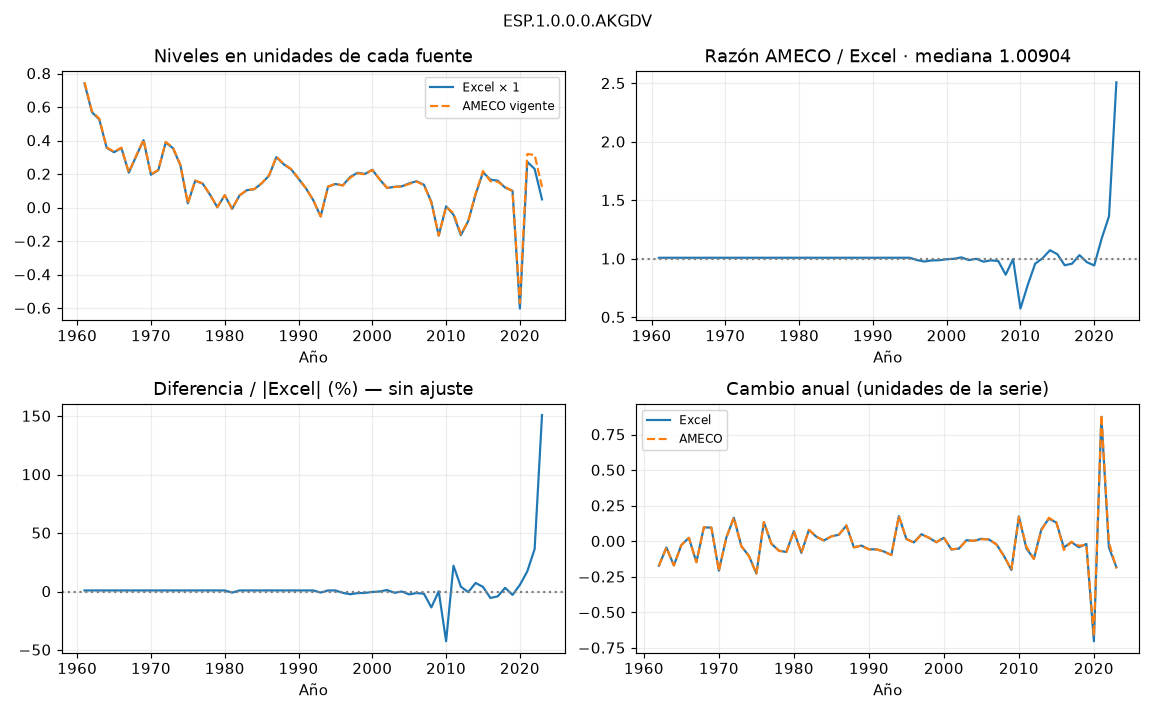

In [8]:
show('ESP.1.0.0.0.AKGDV', detail=False)

### `ESP.1.0.0.0.AKNDV`

Net capital stock per unit of gross domestic product at constant prices :- Capital output ratio: total economy

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** K, fila 6

**Unidad Excel:** `capital output ratio` · **Unidad actual:** `capital output ratio`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Net capital stock per unit of gross domestic product at constant prices :- Capital output ratio: total economy',
 'new_title': 'Net capital stock per unit of gross domestic product at constant prices :- Capital output ratio: total economy',
 'n_overlap': 64,
 'equal_values': 1,
 'median_ratio': 1.0206224525257253,
 'max_abs_relative_diff_pct': 4.312162263606764,
 'mean_abs_growth_difference_pp': 0.1286941600600838}

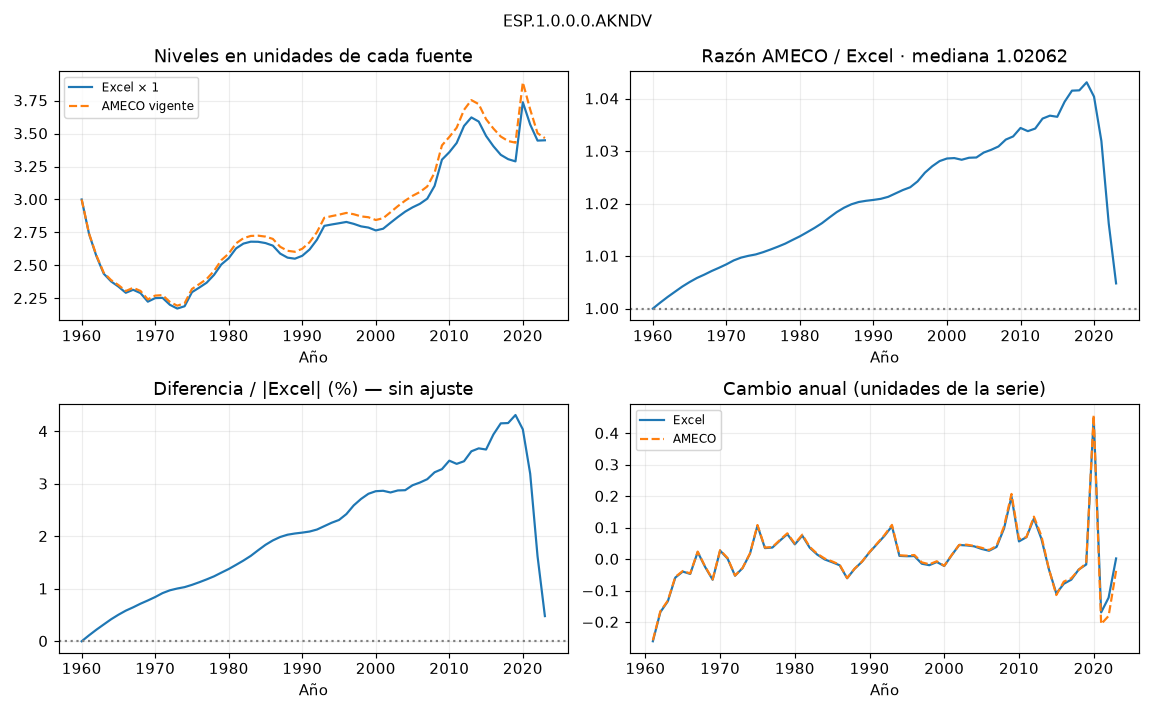

In [9]:
show('ESP.1.0.0.0.AKNDV', detail=False)

### `ESP.1.0.0.0.AMGT`

Share of imports of goods in world imports including intra EU imports :- Foreign trade statistics

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 48

**Unidad Excel:** `(vacía)` · **Unidad actual:** `Share`

La unidad antigua está vacía. La actual dice Share. Comprobar denominador y si se expresa en porcentaje antes de aceptar.

{'original_title': 'Share of imports of goods in world imports including intra EU imports :- Foreign trade statistics ',
 'new_title': 'Share of imports of goods in world imports including intra EU imports :- Foreign trade statistics',
 'n_overlap': 40,
 'equal_values': 0,
 'median_ratio': 1.0011734545454545,
 'max_abs_relative_diff_pct': 5.998181818181831,
 'mean_abs_growth_difference_pp': 2.619800673845122}

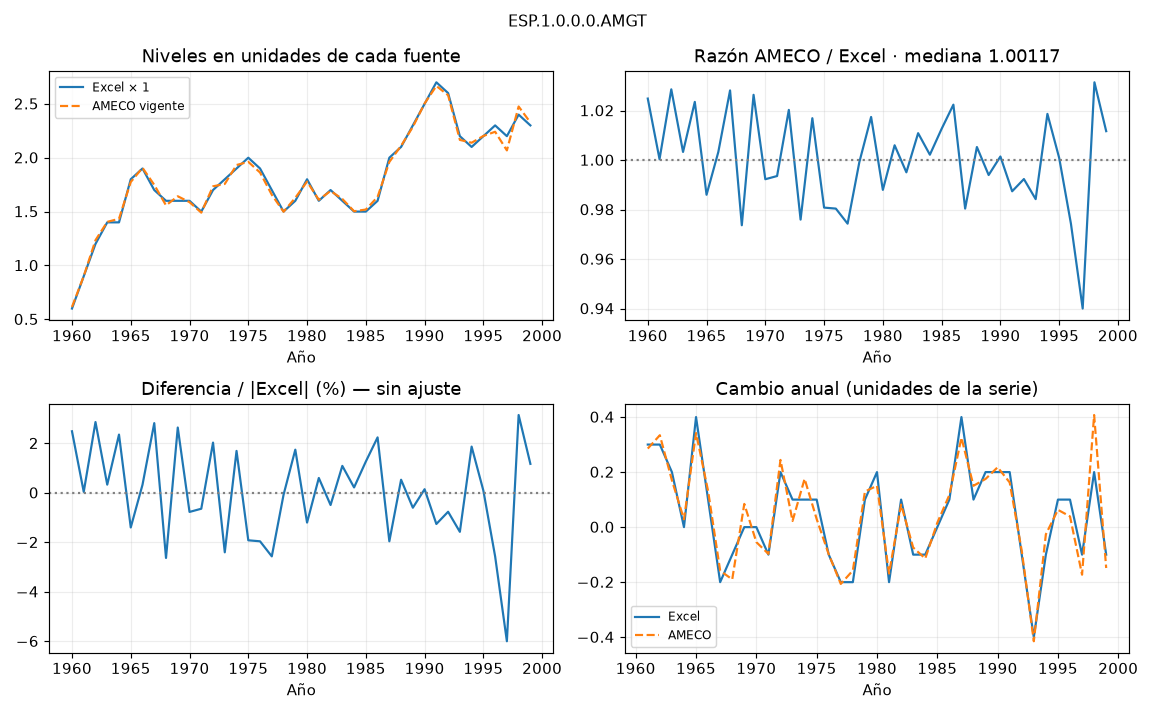

In [10]:
show('ESP.1.0.0.0.AMGT', detail=False)

### `ESP.1.0.0.0.AXGT`

Share of exports of goods in world exports including intra EU exports :- Foreign trade statistics

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 47

**Unidad Excel:** `(vacía)` · **Unidad actual:** `Share`

La unidad antigua está vacía. La actual dice Share. No confundir con AXGE (excluye comercio intra-UE).

{'original_title': 'Share of exports of goods in world exports including intra EU exports :- Foreign trade statistics ',
 'new_title': 'Share of exports of goods in world exports including intra EU exports :- Foreign trade statistics',
 'n_overlap': 40,
 'equal_values': 0,
 'median_ratio': 1.0140263636363636,
 'max_abs_relative_diff_pct': 7.780000000000009,
 'mean_abs_growth_difference_pp': 3.950890292169066}

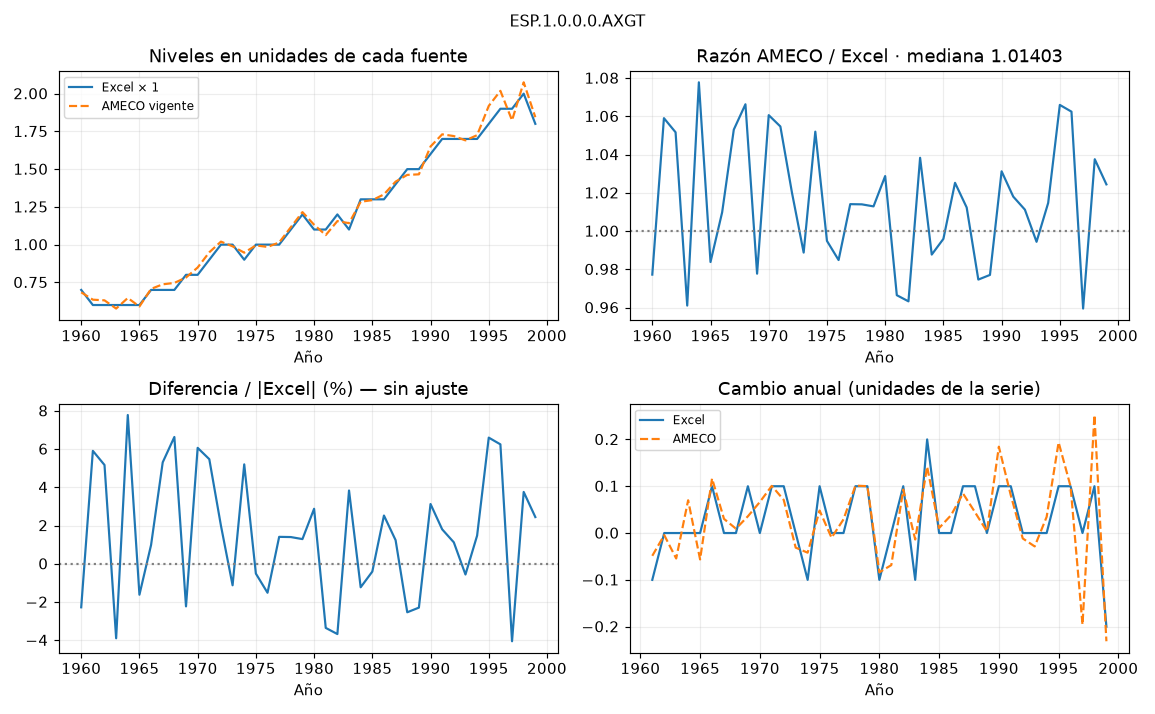

In [11]:
show('ESP.1.0.0.0.AXGT', detail=False)

### `ESP.1.0.0.0.NETN`

Employment, persons: total economy (National accounts)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** mercado traballo, fila 11

**Unidad Excel:** `1000 persons` · **Unidad actual:** `1000 persons`

Empleo de contabilidad nacional. La comparación EPA se mantiene separada: no son universos intercambiables.

{'original_title': 'Employment, persons: total economy (National accounts)',
 'new_title': 'Employment, persons: total economy (National accounts)',
 'n_overlap': 65,
 'equal_values': 62,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 0.578810616988459,
 'mean_abs_growth_difference_pp': 0.009308899311380806}

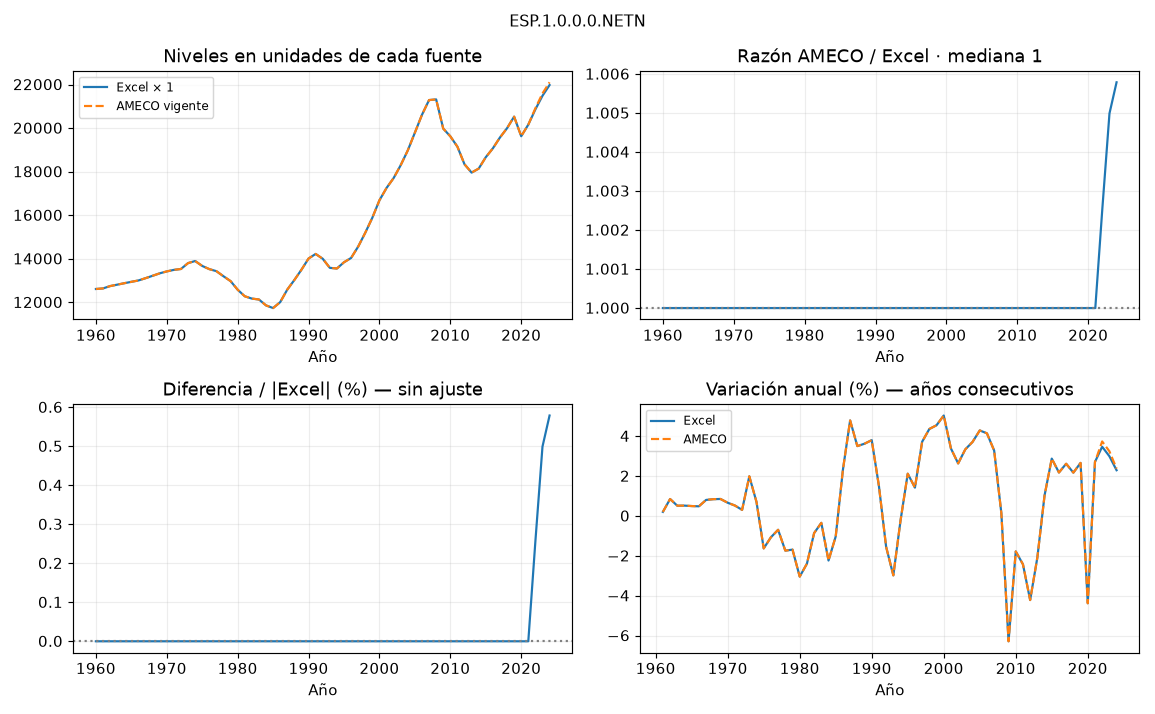

In [12]:
show('ESP.1.0.0.0.NETN', detail=False)

### `ESP.1.0.0.0.UOGD`

Gross operating surplus: total economy

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 19

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross operating surplus: total economy',
 'new_title': 'Gross operating surplus: total economy',
 'n_overlap': 66,
 'equal_values': 29,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 1.5450016463060903,
 'mean_abs_growth_difference_pp': 0.02548083318202076}

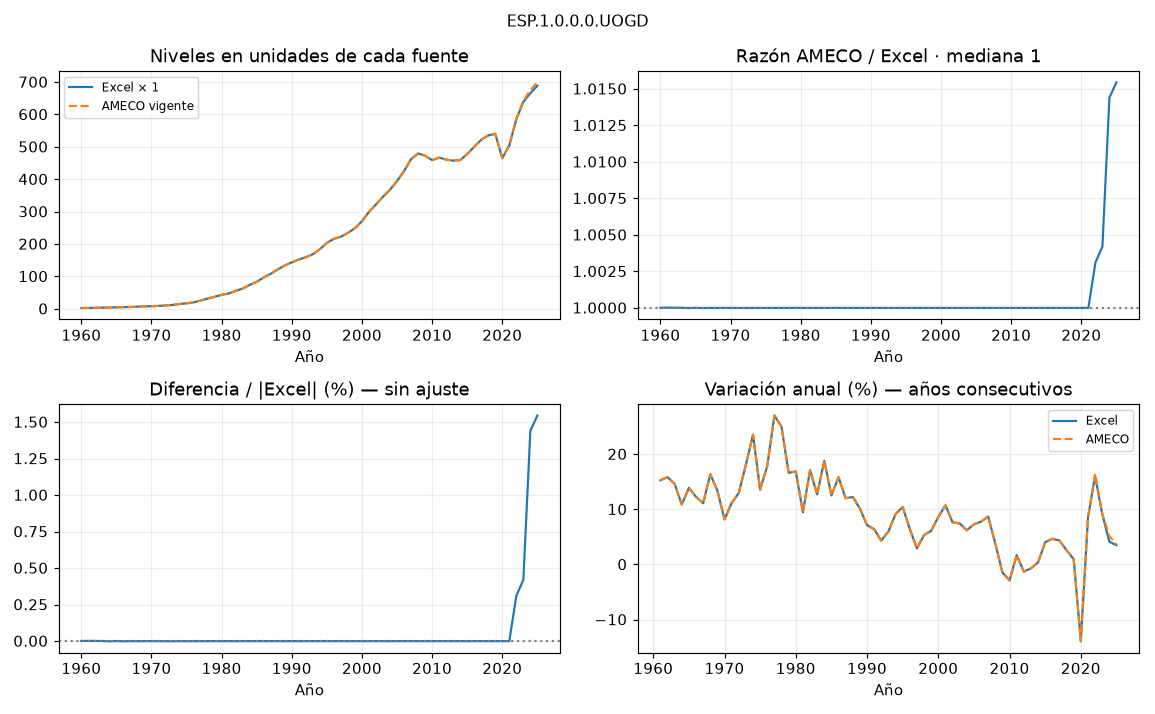

In [13]:
show('ESP.1.0.0.0.UOGD', detail=False)

### `ESP.1.0.0.0.URTG`

Total revenue: general government :- ESA 2010

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** REAL, fila 35

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

La razón AMECO/Excel está cerca de 0,0001. Probar factor_excel=1e-4 solo como hipótesis visual. Silver conserva AMECO sin escalar; falta explicar la escala de la referencia.

{'original_title': 'Total revenue: general government :- ESA 2010 ',
 'new_title': 'Total revenue: general government :- ESA 2010',
 'n_overlap': 27,
 'equal_values': 0,
 'median_ratio': 9.999044840849834e-05,
 'max_abs_relative_diff_pct': 99.99000383639562,
 'mean_abs_growth_difference_pp': 0.1755881546254377}

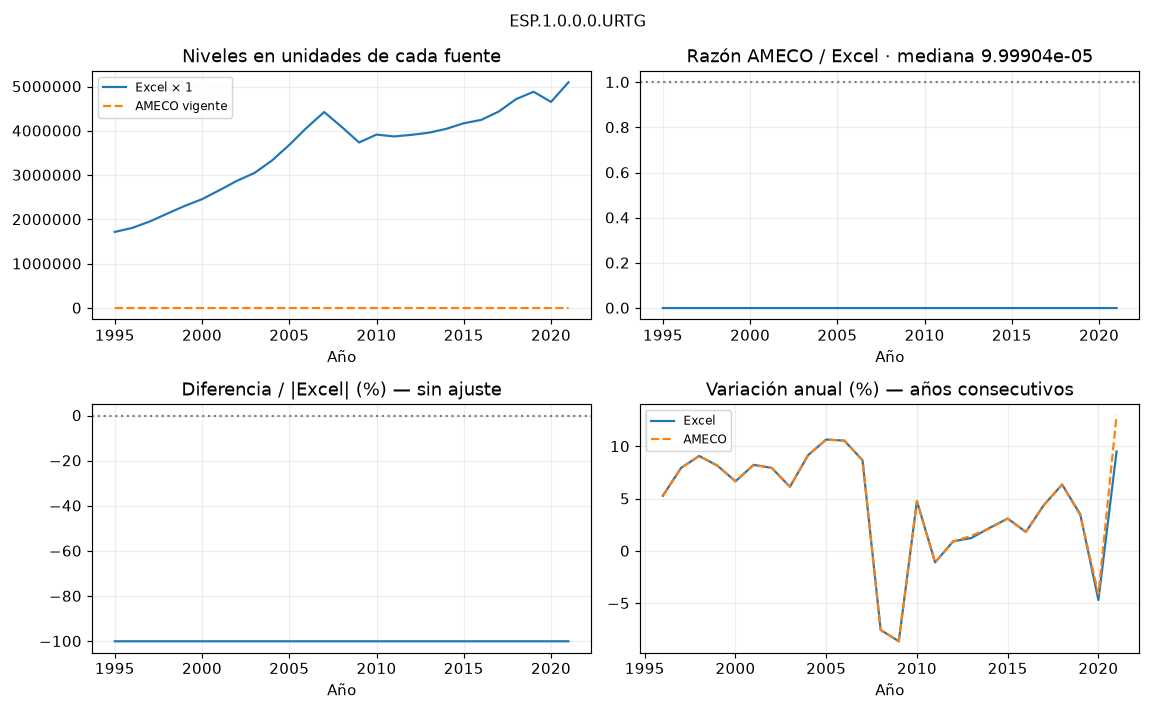

In [14]:
show('ESP.1.0.0.0.URTG', detail=False)

### `ESP.1.0.0.0.USGG`

Gross saving: general government :- ESA 2010

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** REAL, fila 30

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross saving: general government :- ESA 2010 ',
 'new_title': 'Gross saving: general government :- ESA 2010',
 'n_overlap': 28,
 'equal_values': 0,
 'median_ratio': 0.998117785933281,
 'max_abs_relative_diff_pct': 30.975753154214296,
 'mean_abs_growth_difference_pp': 29.14265343917208}

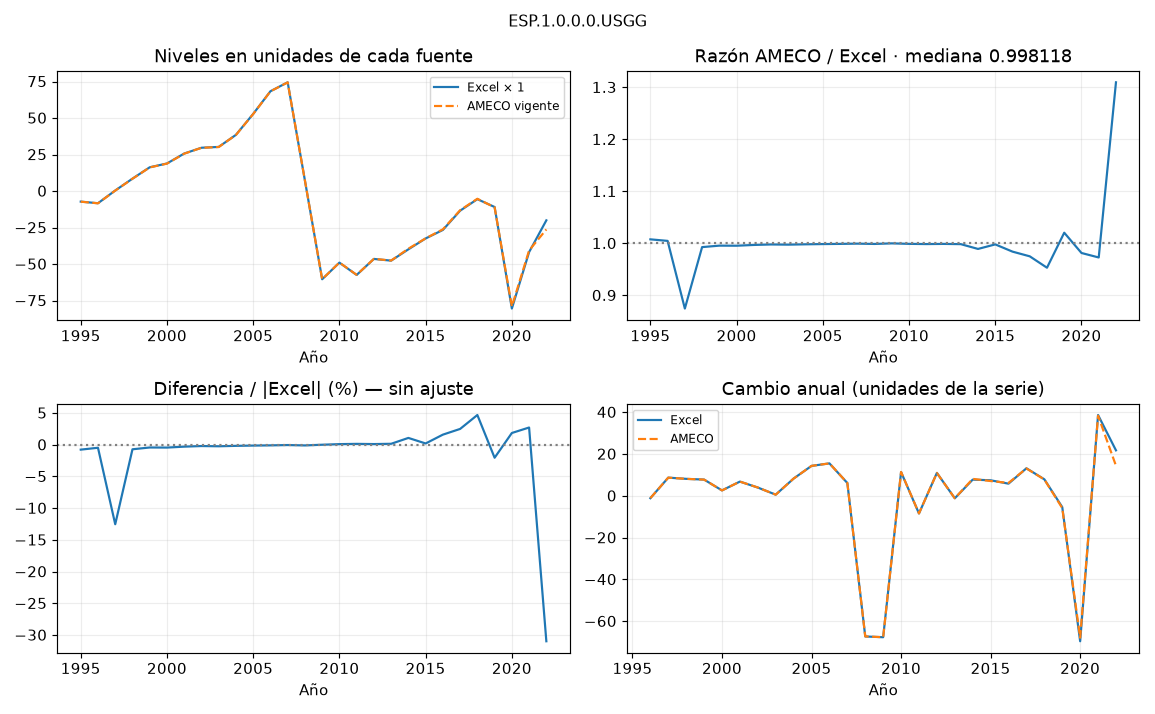

In [15]:
show('ESP.1.0.0.0.USGG', detail=False)

### `ESP.1.0.0.0.USGN`

Gross national saving

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** REAL, fila 31

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross national saving ',
 'new_title': 'Gross national saving',
 'n_overlap': 63,
 'equal_values': 3,
 'median_ratio': 1.0000109968658932,
 'max_abs_relative_diff_pct': 11.253215276847099,
 'mean_abs_growth_difference_pp': 0.2665398314004279}

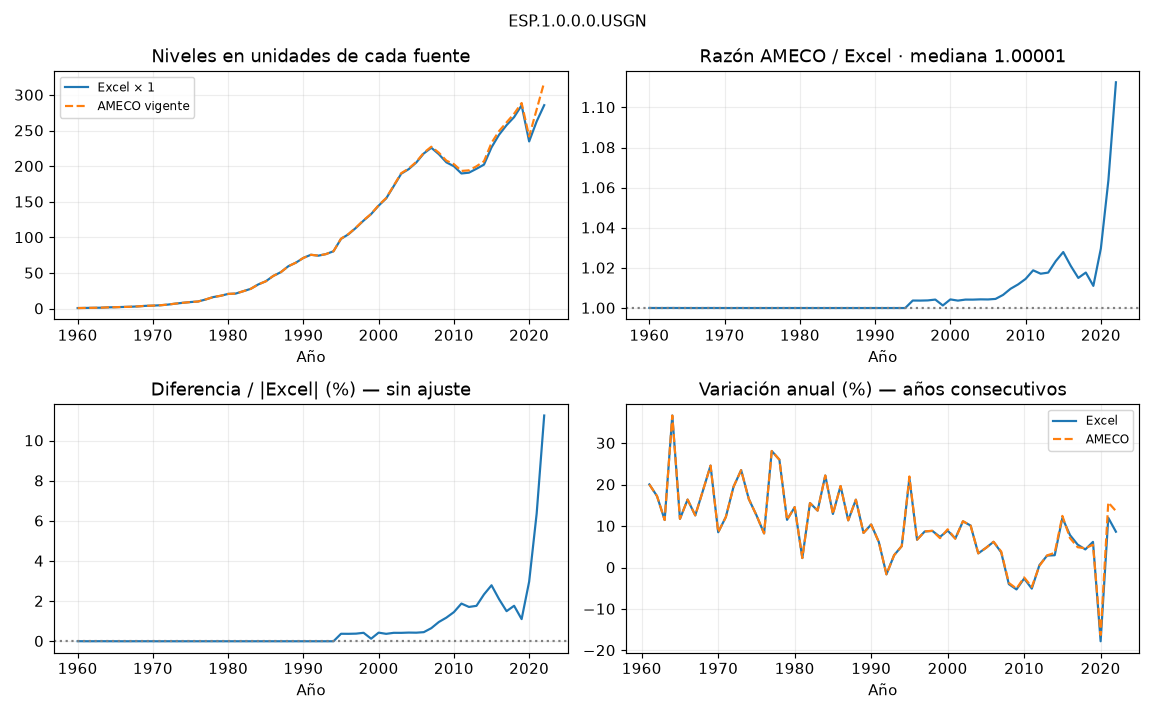

In [16]:
show('ESP.1.0.0.0.USGN', detail=False)

### `ESP.1.0.0.0.USGP`

Gross saving: private sector :- ESA 2010

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** REAL, fila 29

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross saving: private sector :- ESA 2010 ',
 'new_title': 'Gross saving: private sector :- ESA 2010',
 'n_overlap': 28,
 'equal_values': 0,
 'median_ratio': 1.0099872671596084,
 'max_abs_relative_diff_pct': 12.546368578084776,
 'mean_abs_growth_difference_pp': 0.5946774873233148}

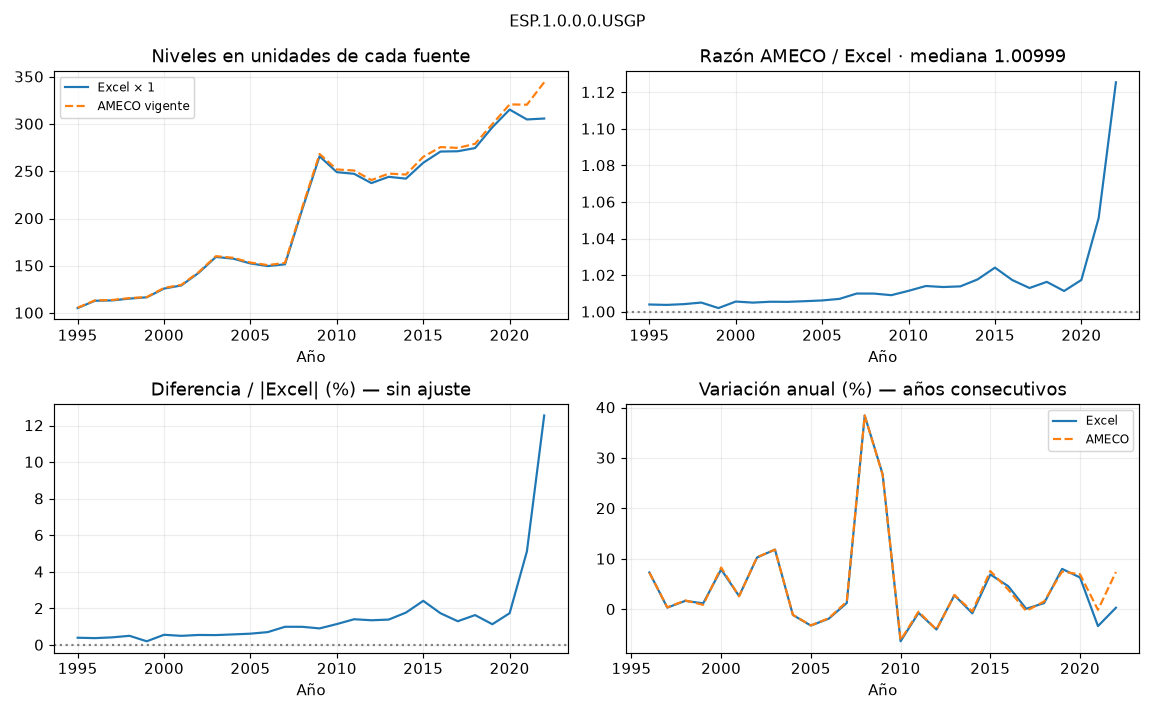

In [17]:
show('ESP.1.0.0.0.USGP', detail=False)

### `ESP.1.0.0.0.UTVT`

Taxes linked to imports and production: total economy

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 20

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Taxes linked to imports and production: total economy',
 'new_title': 'Taxes linked to imports and production: total economy',
 'n_overlap': 66,
 'equal_values': 28,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 2.022389144250317,
 'mean_abs_growth_difference_pp': 0.04401911442829805}

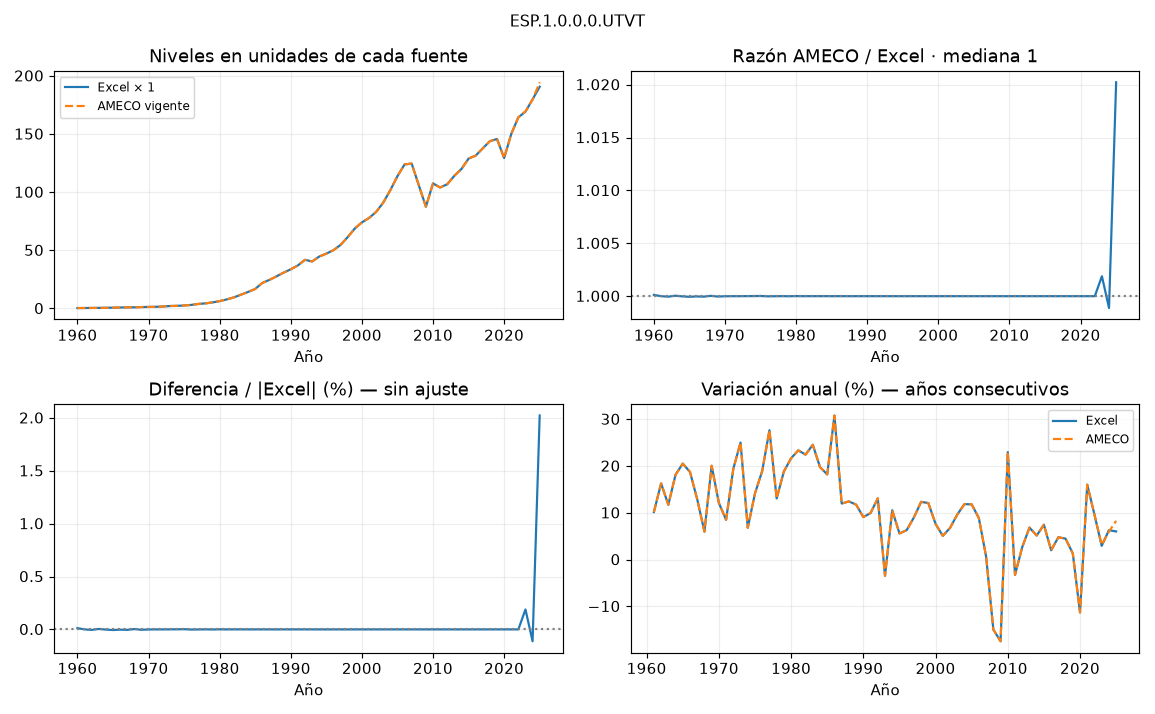

In [18]:
show('ESP.1.0.0.0.UTVT', detail=False)

### `ESP.1.0.0.0.UUTG`

Total expenditure: general government :- ESA 2010 (Including one-off proceeds (treated as negative expenditure) relative to the allocation of mobile phone licences (UMTS))

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** REAL, fila 36

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `(National currency)`

La razón está cerca de 0,0001 y la unidad literal cambia. Revisar también el título y los ajustes UMTS; no aceptar por parecido tras reescalar.

{'original_title': 'Total expenditure: general government :- ESA 2010 ',
 'new_title': 'Total expenditure: general government :- ESA 2010 (Including one-off proceeds (treated as negative expenditure) relative to the allocation of mobile phone licences (UMTS))',
 'n_overlap': 28,
 'equal_values': 0,
 'median_ratio': 9.998833797137728e-05,
 'max_abs_relative_diff_pct': 99.99013794475071,
 'mean_abs_growth_difference_pp': 0.48398230310423235}

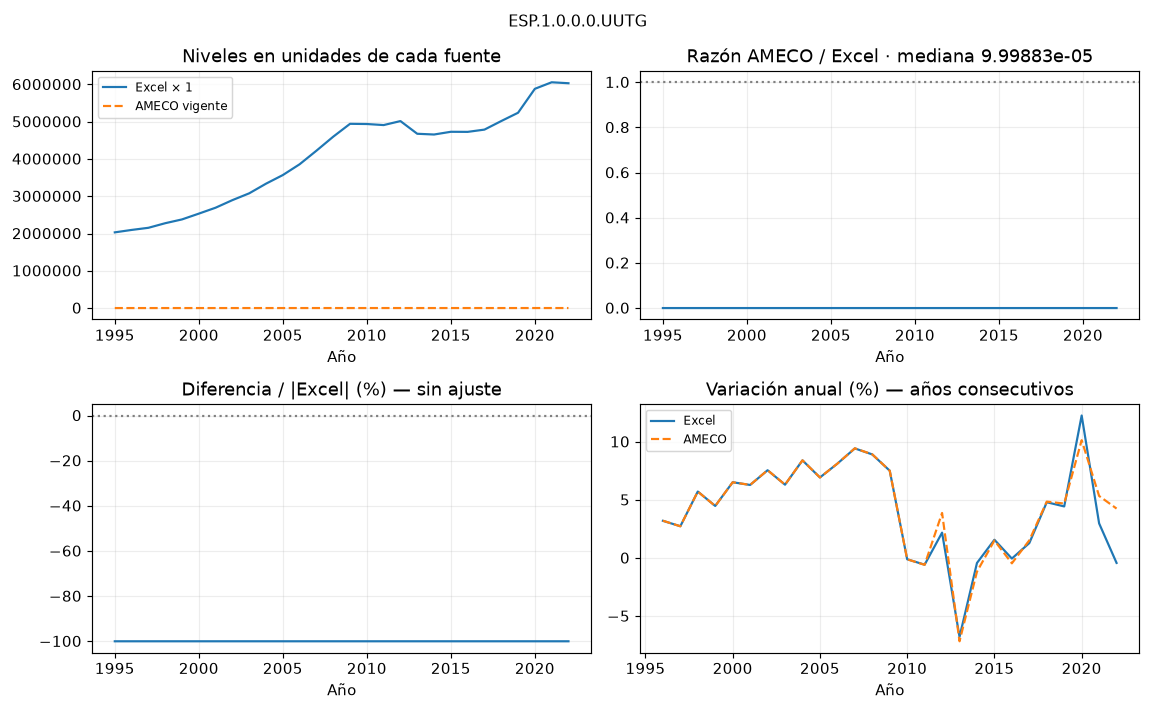

In [19]:
show('ESP.1.0.0.0.UUTG', detail=False)

### `ESP.1.0.0.0.UVGM`

Gross value added at current prices: manufacturing industry

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 66

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross value added at current prices: manufacturing industry ',
 'new_title': 'Gross value added at current prices: manufacturing industry',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 0.9786456787291672,
 'max_abs_relative_diff_pct': 7.037442922374432,
 'mean_abs_growth_difference_pp': 0.47363753445561524}

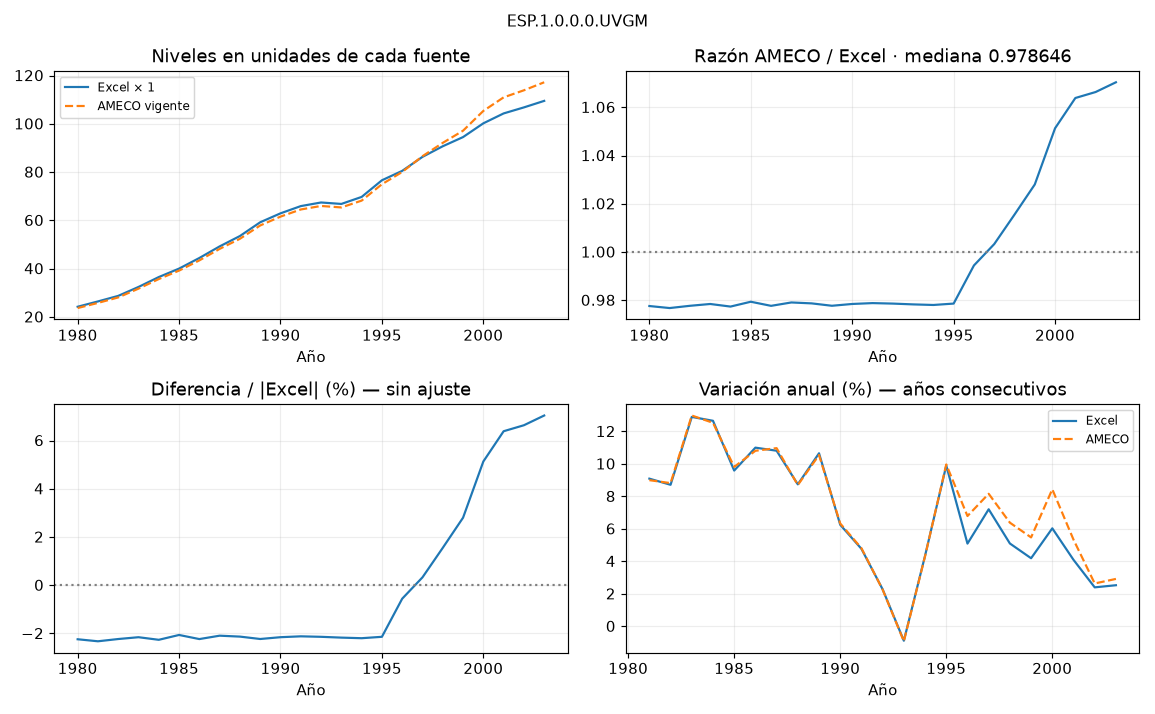

In [20]:
show('ESP.1.0.0.0.UVGM', detail=False)

### `ESP.1.0.0.0.UVGN`

Gross national income at current prices

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 56

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross national income at current market prices ',
 'new_title': 'Gross national income at current prices',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 1.0540131654264453,
 'max_abs_relative_diff_pct': 9.765969285555302,
 'mean_abs_growth_difference_pp': 0.3307183580902139}

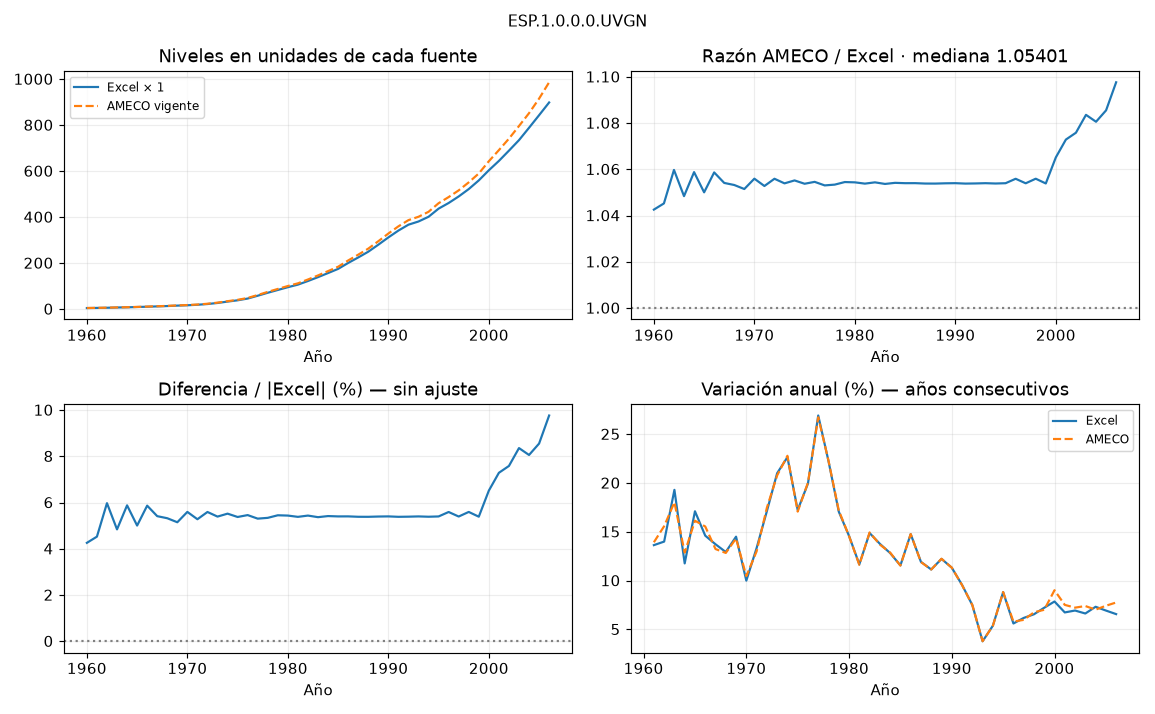

In [21]:
show('ESP.1.0.0.0.UVGN', detail=False)

### `ESP.1.0.0.0.UVGT`

Gross national disposable income

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 57

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross national disposable income ',
 'new_title': 'Gross national disposable income',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 1.0482987059669304,
 'max_abs_relative_diff_pct': 8.781438463256647,
 'mean_abs_growth_difference_pp': 0.26286388527554094}

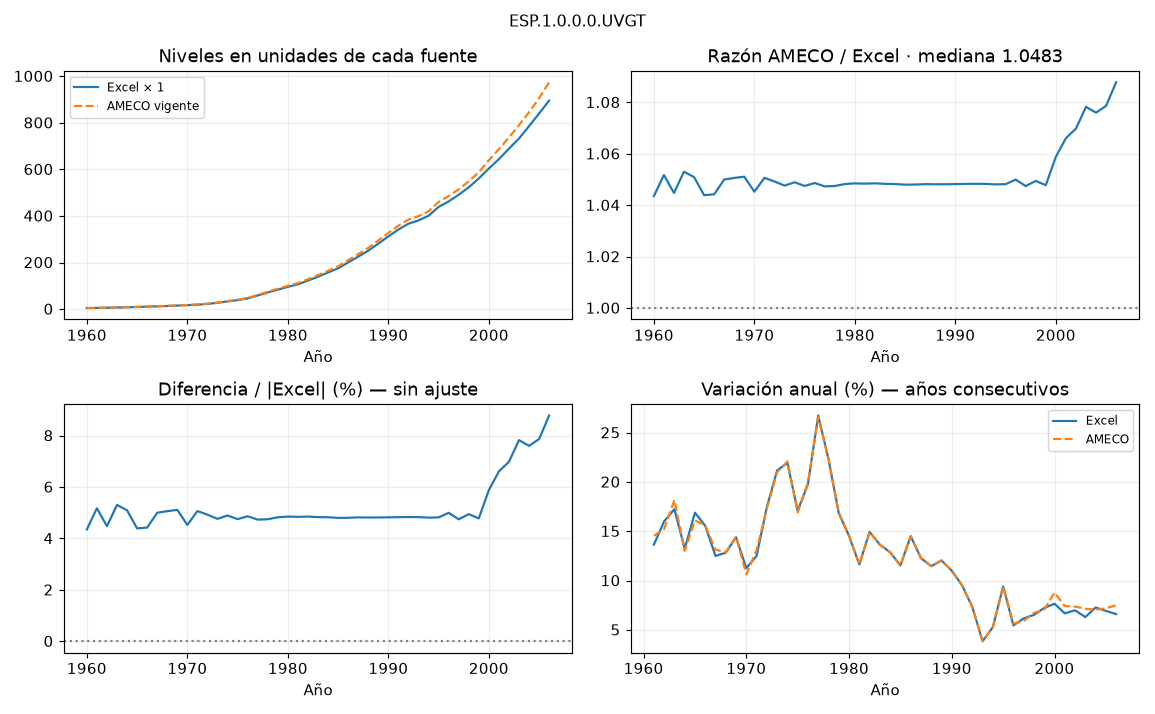

In [22]:
show('ESP.1.0.0.0.UVGT', detail=False)

### `ESP.1.0.0.0.UVNN`

National income at current prices

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 58

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'National income at current market prices ',
 'new_title': 'National income at current prices',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 1.0663278634028408,
 'max_abs_relative_diff_pct': 12.946534653465354,
 'mean_abs_growth_difference_pp': 0.3275276590364572}

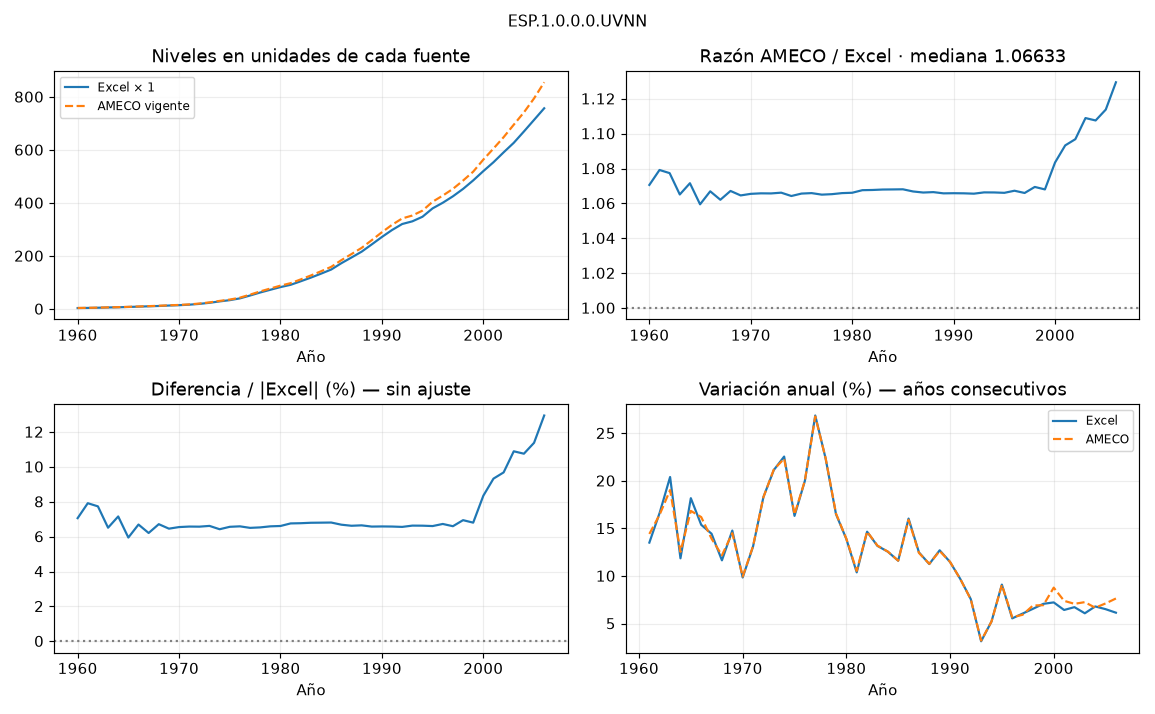

In [23]:
show('ESP.1.0.0.0.UVNN', detail=False)

### `ESP.1.0.0.0.UVNT`

National disposable income

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 59

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'National disposable income ',
 'new_title': 'National disposable income',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 1.059636,
 'max_abs_relative_diff_pct': 11.806152214266762,
 'mean_abs_growth_difference_pp': 0.323921664600967}

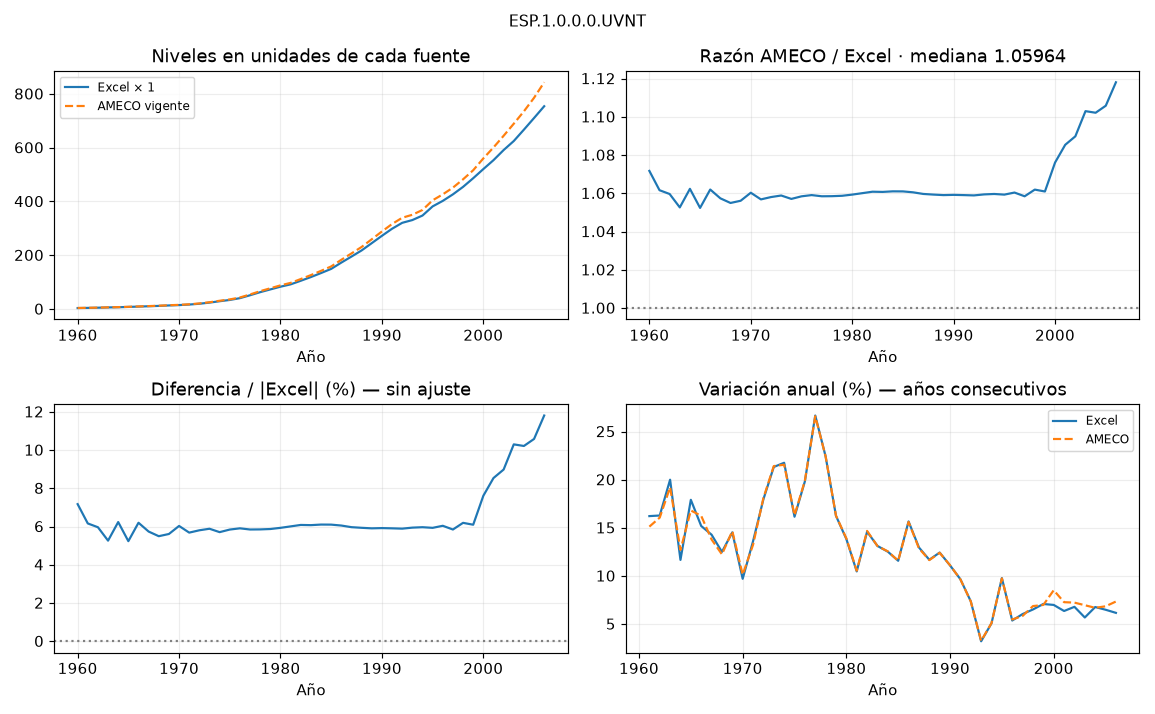

In [24]:
show('ESP.1.0.0.0.UVNT', detail=False)

### `ESP.1.0.0.0.UWCD`

Compensation of employees: total economy

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 18

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Remuneración de asalariados: revisar los años discrepantes y preservar el agregado D.1.

{'original_title': 'Compensation of employees: total economy',
 'new_title': 'Compensation of employees: total economy',
 'n_overlap': 66,
 'equal_values': 27,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 0.8829560793271723,
 'mean_abs_growth_difference_pp': 0.03756468463084314}

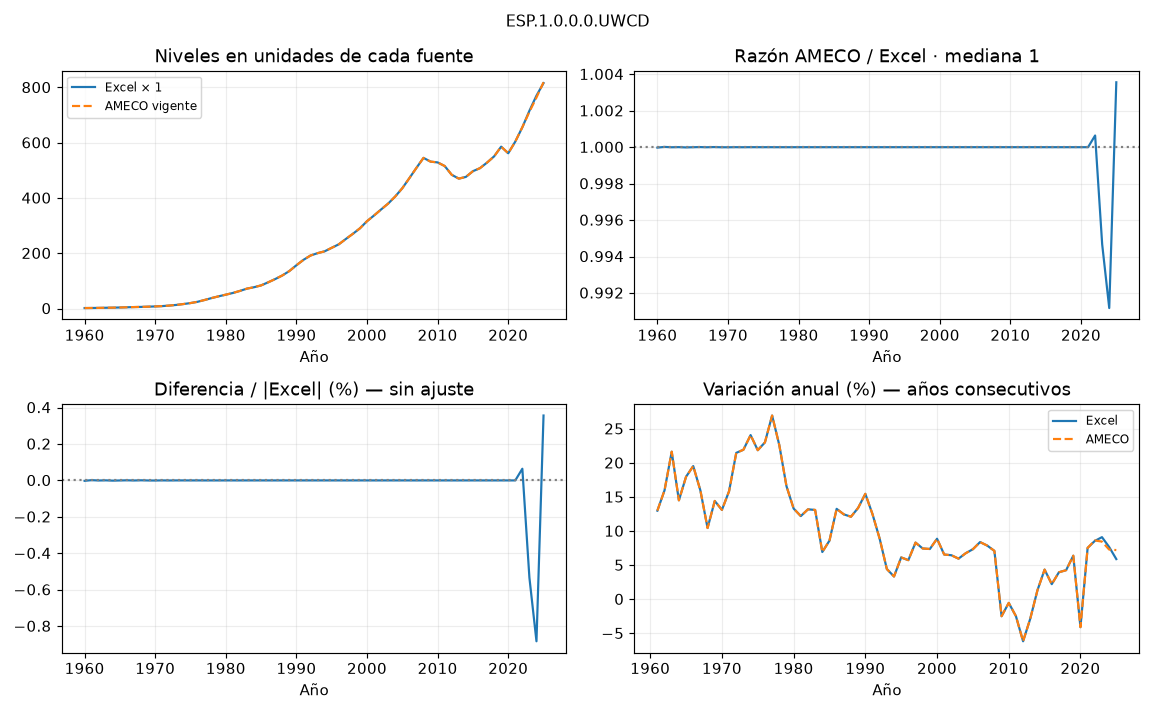

In [25]:
show('ESP.1.0.0.0.UWCD', detail=False)

### `ESP.1.0.0.0.UYGD`

Gross domestic product at current factor cost

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 17

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross domestic product at current factor cost',
 'new_title': 'Gross domestic product at current factor cost',
 'n_overlap': 66,
 'equal_values': 27,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 0.899051436933816,
 'mean_abs_growth_difference_pp': 0.024061945715598148}

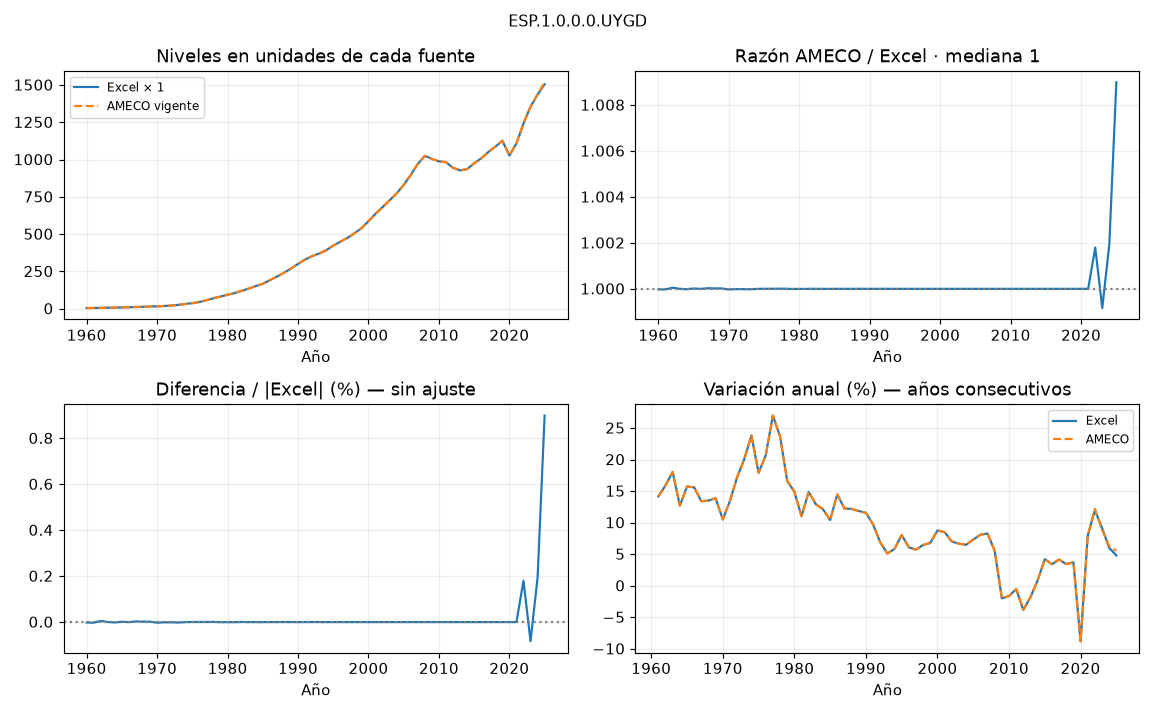

In [26]:
show('ESP.1.0.0.0.UYGD', detail=False)

### `ESP.1.0.0.0.UYVT`

Subsidies: total economy

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 21

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Subsidies: total economy',
 'new_title': 'Subsidies: total economy',
 'n_overlap': 66,
 'equal_values': 63,
 'median_ratio': 1.0,
 'max_abs_relative_diff_pct': 2.699290892553345,
 'mean_abs_growth_difference_pp': 0.06999042276421931}

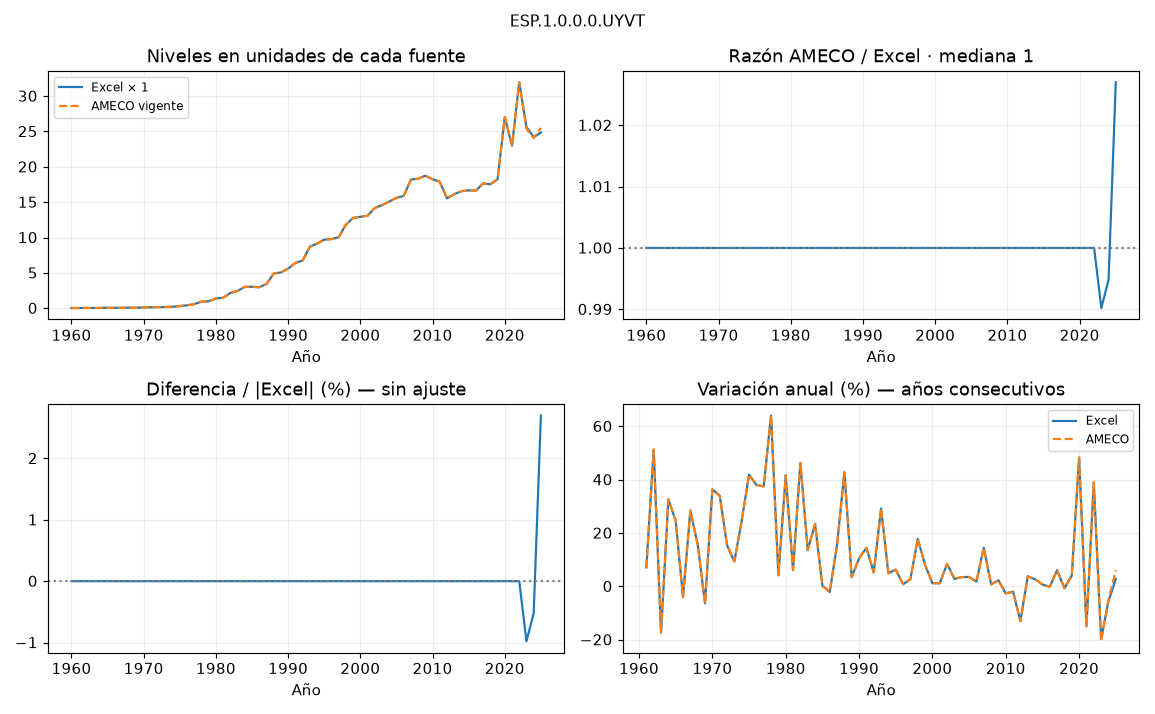

In [27]:
show('ESP.1.0.0.0.UYVT', detail=False)

### `ESP.1.0.99.0.DMGE`

Extra EU imports of goods :- Foreign trade statistics (1960-1998 Former EU-15)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 46

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Extra EU imports of goods :- Foreign trade statistics ',
 'new_title': 'Extra EU imports of goods :- Foreign trade statistics (1960-1998 Former EU-15)',
 'n_overlap': 44,
 'equal_values': 0,
 'median_ratio': 1.0000331562296596,
 'max_abs_relative_diff_pct': 33.33740314627846,
 'mean_abs_growth_difference_pp': 1.908625542807195}

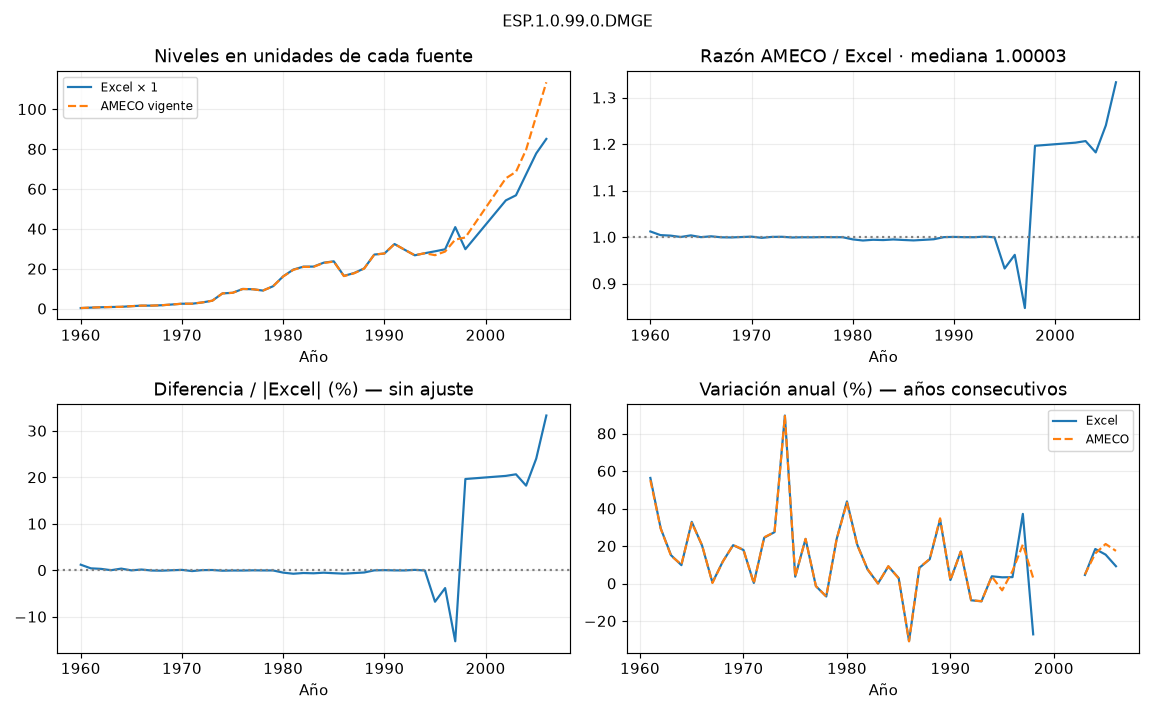

In [28]:
show('ESP.1.0.99.0.DMGE', detail=False)

### `ESP.1.0.99.0.DMGI`

Intra EU imports of goods :- Foreign trade statistics (1960-1998 Former EU-15)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 45

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Intra EU imports of goods :- Foreign trade statistics ',
 'new_title': 'Intra EU imports of goods :- Foreign trade statistics (1960-1998 Former EU-15)',
 'n_overlap': 44,
 'equal_values': 0,
 'median_ratio': 0.9996899575596317,
 'max_abs_relative_diff_pct': 10.394619105199517,
 'mean_abs_growth_difference_pp': 1.3508958131819422}

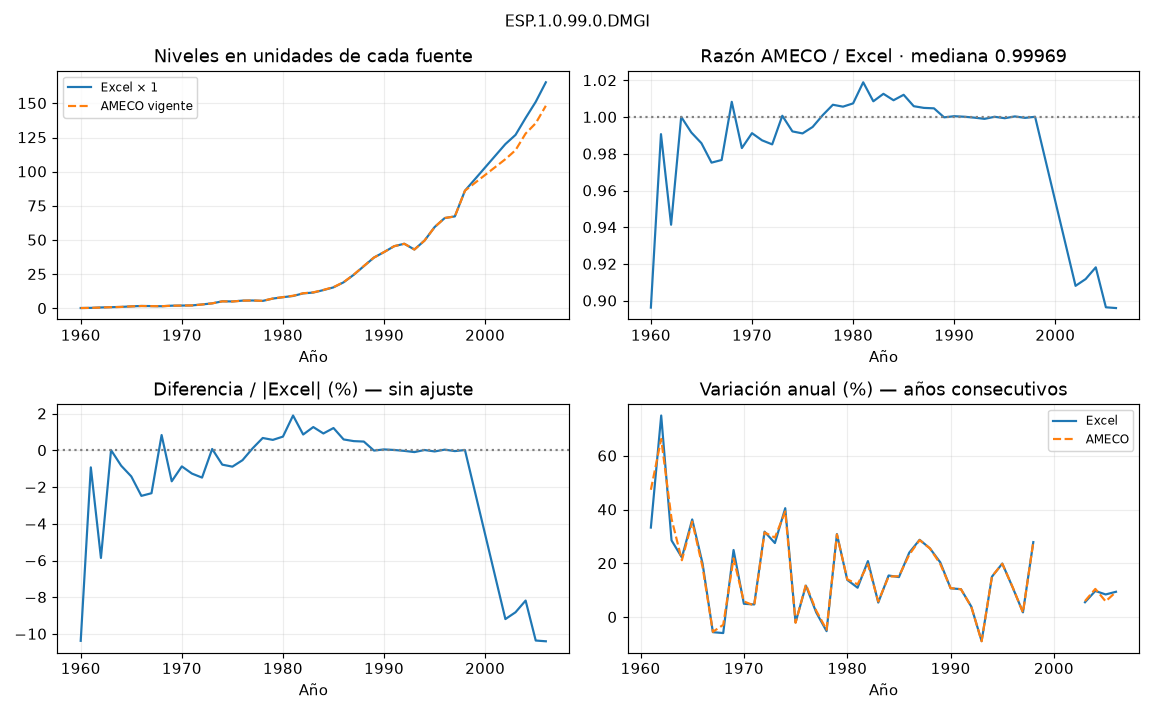

In [29]:
show('ESP.1.0.99.0.DMGI', detail=False)

### `ESP.1.0.99.0.DMGT`

Total imports of goods :- Foreign trade statistics

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 44

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Total imports of goods :- Foreign trade statistics ',
 'new_title': 'Total imports of goods :- Foreign trade statistics',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 1.0000447435897435,
 'max_abs_relative_diff_pct': 5.7316081330868744,
 'mean_abs_growth_difference_pp': 1.3580633421476336}

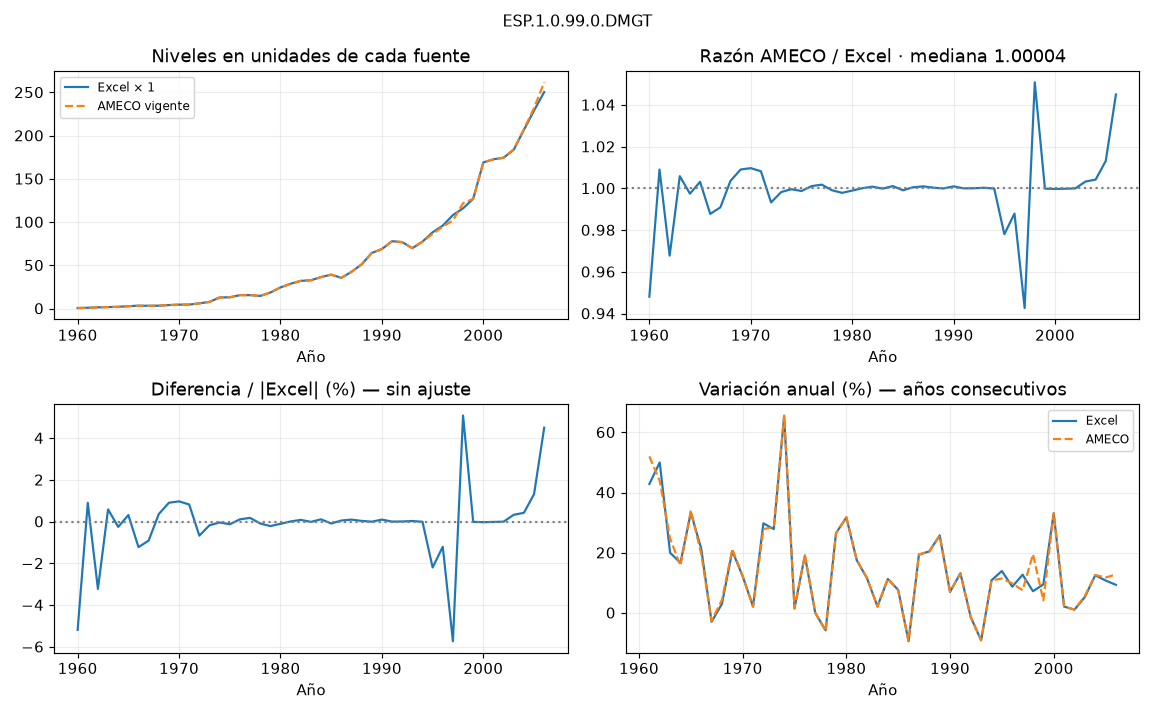

In [30]:
show('ESP.1.0.99.0.DMGT', detail=False)

### `ESP.1.0.99.0.DXGE`

Extra EU exports of goods :- Foreign trade statistics (1960-1998 Former EU-15)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 43

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Extra EU exports of goods :- Foreign trade statistics ',
 'new_title': 'Extra EU exports of goods :- Foreign trade statistics (1960-1998 Former EU-15)',
 'n_overlap': 44,
 'equal_values': 0,
 'median_ratio': 1.000252375026761,
 'max_abs_relative_diff_pct': 40.02490464437963,
 'mean_abs_growth_difference_pp': 2.389880307599151}

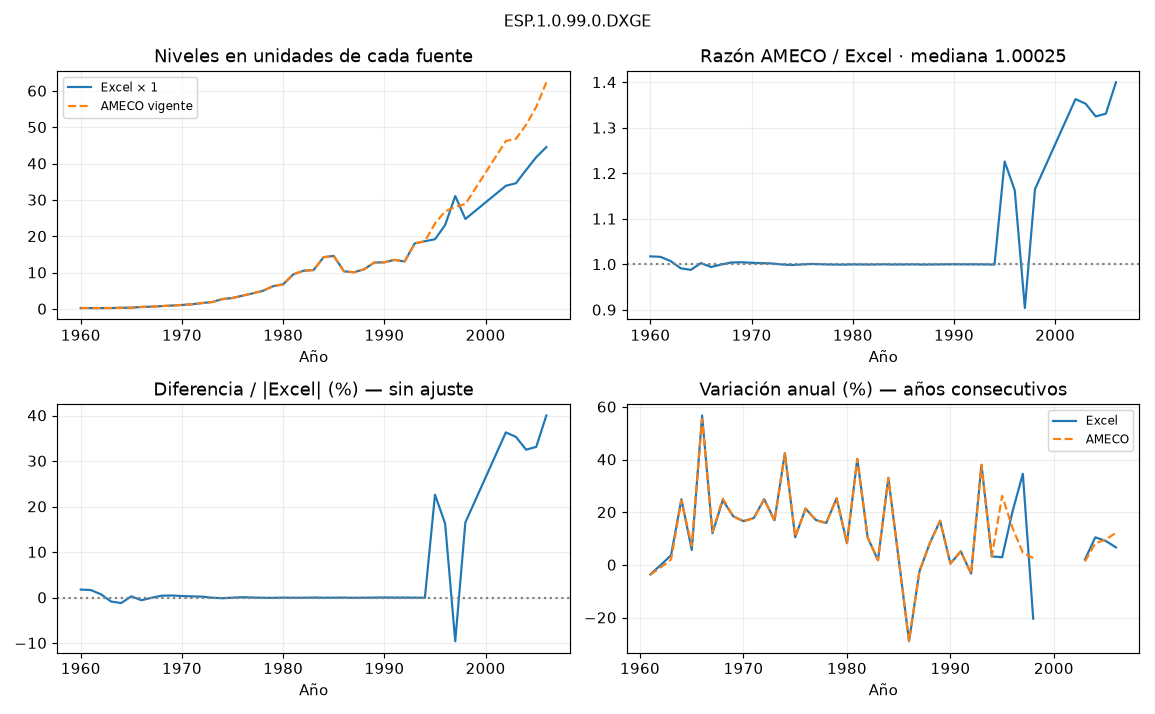

In [31]:
show('ESP.1.0.99.0.DXGE', detail=False)

### `ESP.1.0.99.0.DXGI`

Intra EU exports of goods :- Foreign trade statistics (1960-1998 Former EU-15)

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 42

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Intra EU exports of goods :- Foreign trade statistics ',
 'new_title': 'Intra EU exports of goods :- Foreign trade statistics (1960-1998 Former EU-15)',
 'n_overlap': 44,
 'equal_values': 0,
 'median_ratio': 0.9991564724919094,
 'max_abs_relative_diff_pct': 13.942064180398955,
 'mean_abs_growth_difference_pp': 1.8653226206833433}

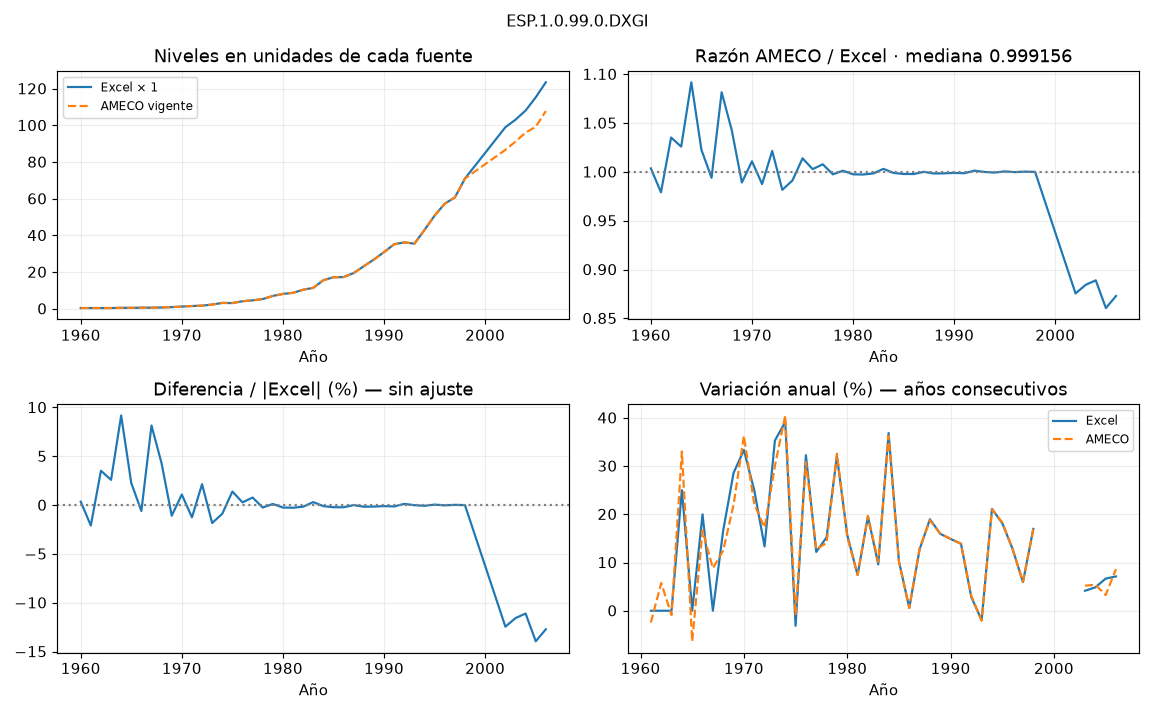

In [32]:
show('ESP.1.0.99.0.DXGI', detail=False)

### `ESP.1.0.99.0.DXGT`

Total exports of goods :- Foreign trade statistics

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 41

**Unidad Excel:** `(Mrd EUR)` · **Unidad actual:** `(Mrd EUR)`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Total exports of goods :- Foreign trade statistics ',
 'new_title': 'Total exports of goods :- Foreign trade statistics',
 'n_overlap': 47,
 'equal_values': 0,
 'median_ratio': 0.9996792018419032,
 'max_abs_relative_diff_pct': 6.263571428571432,
 'mean_abs_growth_difference_pp': 1.4804493367321931}

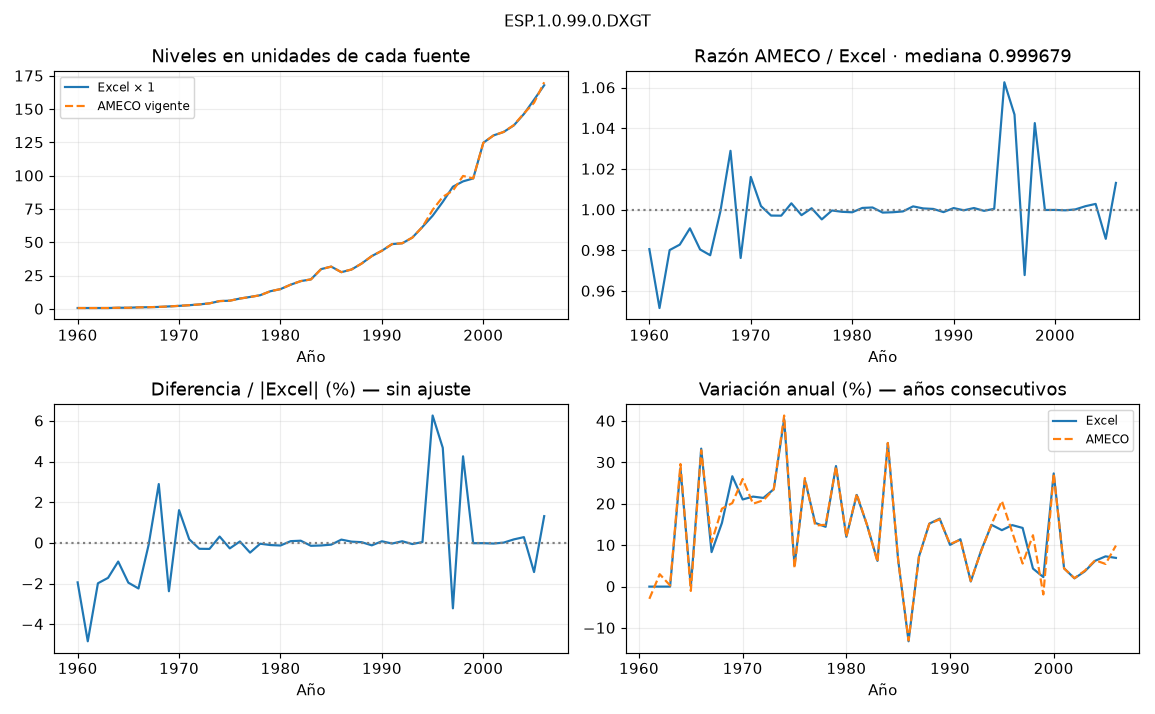

In [33]:
show('ESP.1.0.99.0.DXGT', detail=False)

### `ESP.1.1.0.0.UVG0`

Gross Value Added at current prices: total of branches

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 63

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross Value Added at current prices: total of branches ',
 'new_title': 'Gross Value Added at current prices: total of branches',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 1.0087789971859316,
 'max_abs_relative_diff_pct': 4.69906542056075,
 'mean_abs_growth_difference_pp': 0.20842278215345206}

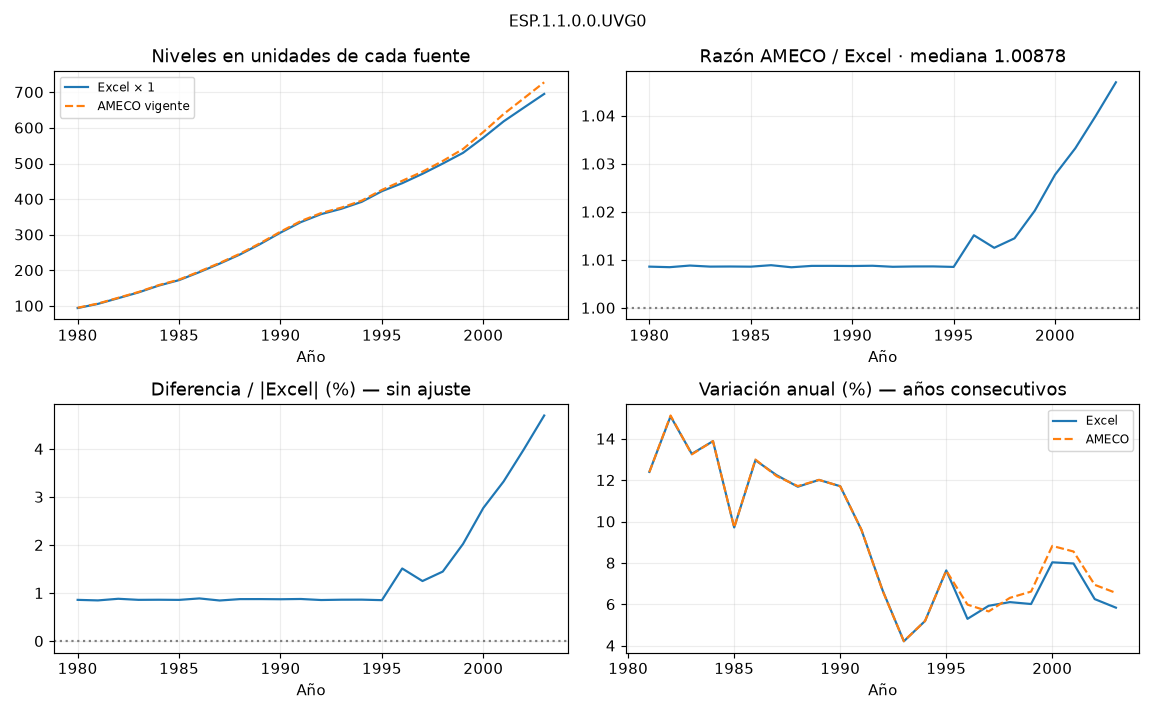

In [34]:
show('ESP.1.1.0.0.UVG0', detail=False)

### `ESP.1.1.0.0.UVG1`

Gross Value Added at current prices: agriculture, forestry and fishery products

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 64

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross Value Added at current prices: agriculture, forestry and fishery products ',
 'new_title': 'Gross Value Added at current prices: agriculture, forestry and fishery products',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 0.9574272213662044,
 'max_abs_relative_diff_pct': 25.20747834017327,
 'mean_abs_growth_difference_pp': 1.231159934807171}

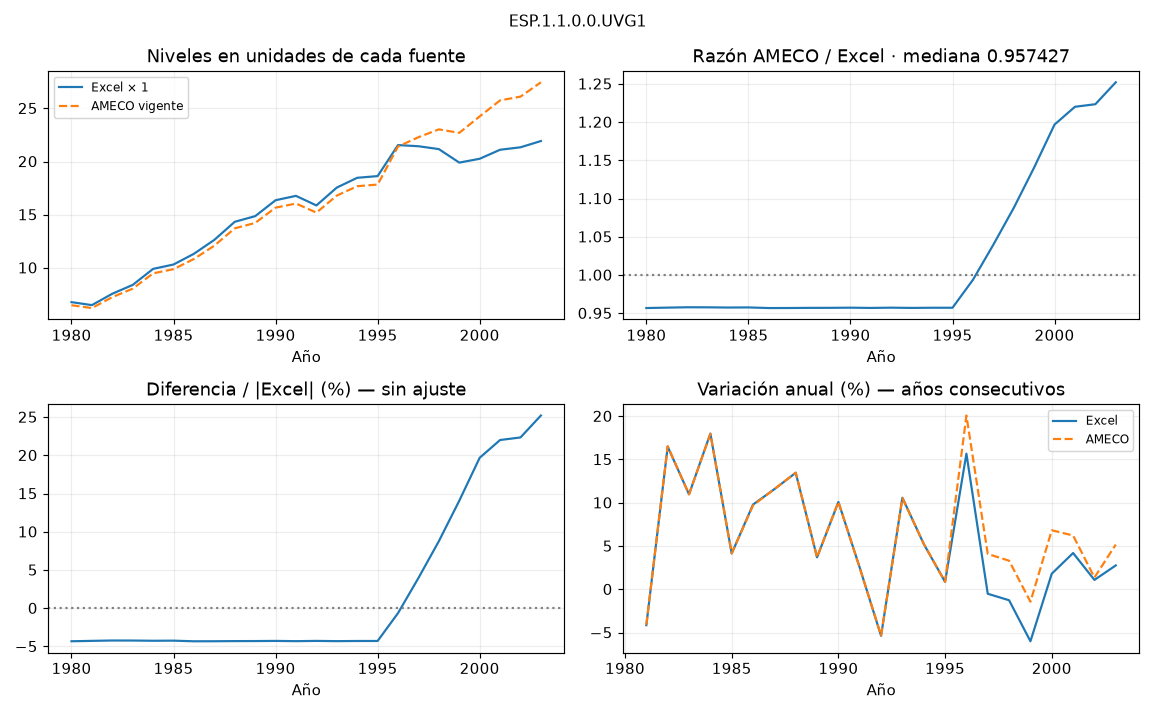

In [35]:
show('ESP.1.1.0.0.UVG1', detail=False)

### `ESP.1.1.0.0.UVG2`

Gross value added at current prices: industry excluding building and construction

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 65

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross value added at current prices: industry excluding building and construction ',
 'new_title': 'Gross value added at current prices: industry excluding building and construction',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 0.977672671586477,
 'max_abs_relative_diff_pct': 6.553585196607557,
 'mean_abs_growth_difference_pp': 0.43479157811542374}

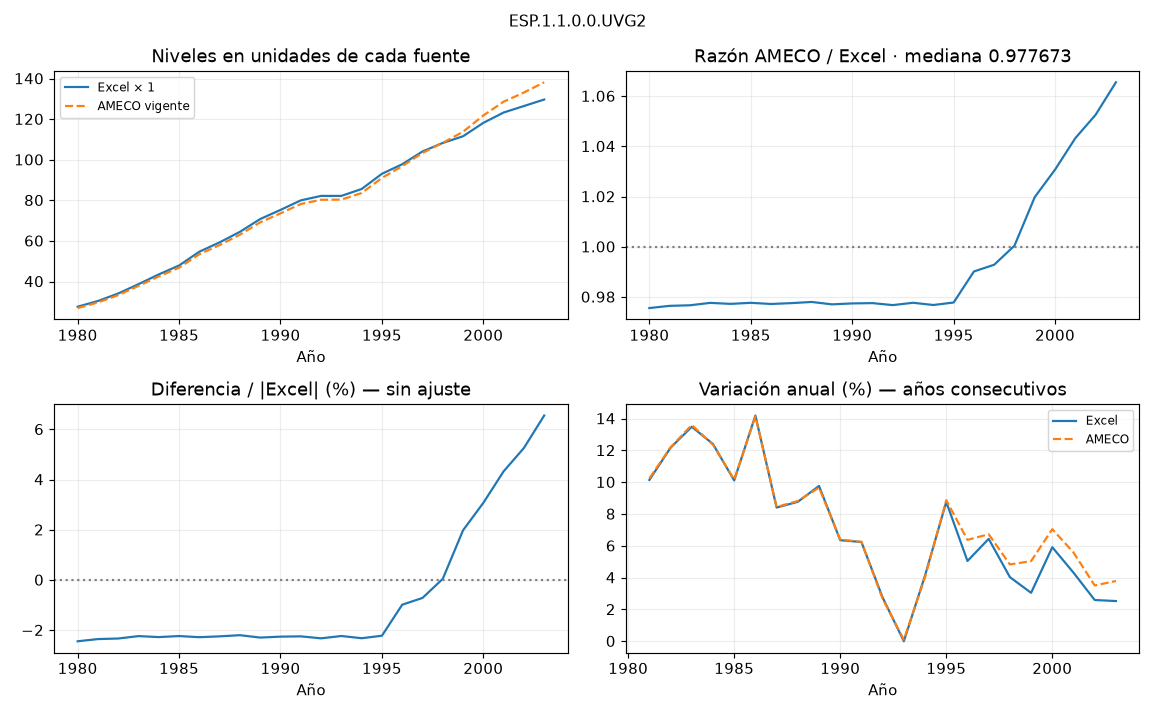

In [36]:
show('ESP.1.1.0.0.UVG2', detail=False)

### `ESP.1.1.0.0.UVG4`

Gross value added at current prices: building and construction

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 67

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

El VAB nominal de construcción presenta diferencias de nivel relevantes. Examinar fechas y alcance de revisión; no es un cambio de base de volumen.

{'original_title': 'Gross value added at current prices: building and construction ',
 'new_title': 'Gross value added at current prices: building and construction',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 1.2397131077039734,
 'max_abs_relative_diff_pct': 26.439416493003847,
 'mean_abs_growth_difference_pp': 0.3870281417558861}

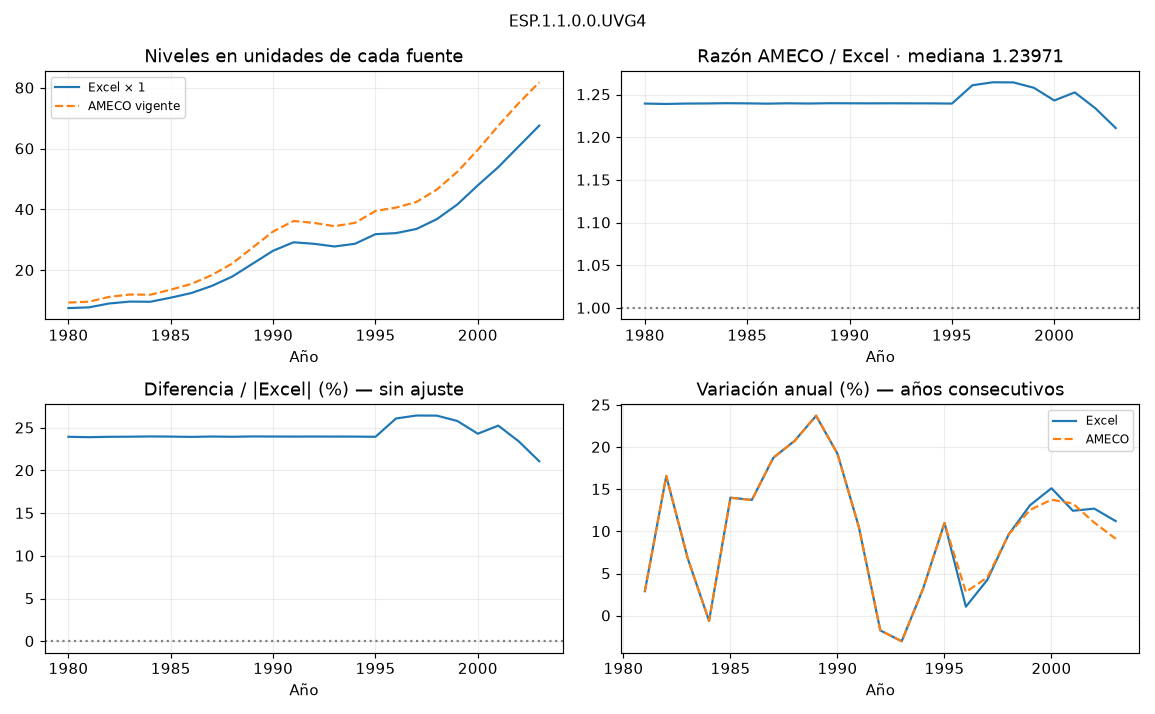

In [37]:
show('ESP.1.1.0.0.UVG4', detail=False)

### `ESP.1.1.0.0.UVG5`

Gross value added at current prices: services

**Estado:** ACEPTADA_REVISION_MANUAL · **Referencia:** NOMINAL, fila 68

**Unidad Excel:** `Mrd EURO-ESP` · **Unidad actual:** `Mrd EURO-ESP`

Comparar fechas, magnitud y patrón de diferencias. La revisión de edición es una hipótesis, no una causa demostrada.

{'original_title': 'Gross value added at current prices: services ',
 'new_title': 'Gross value added at current prices: services',
 'n_overlap': 24,
 'equal_values': 0,
 'median_ratio': 0.9962222254497739,
 'max_abs_relative_diff_pct': 1.3936676940319388,
 'mean_abs_growth_difference_pp': 0.19483656595370966}

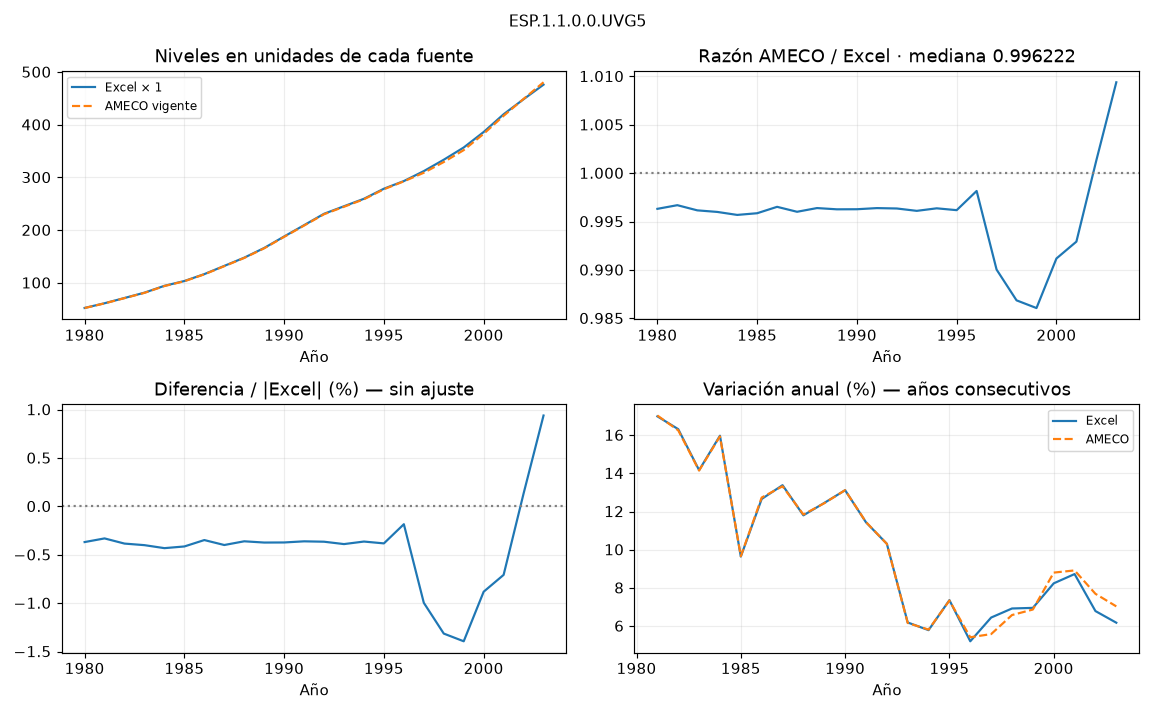

In [38]:
show('ESP.1.1.0.0.UVG5', detail=False)

## 8. Anotaciones del alumno y búsqueda por concepto

Se preservan las 56 anotaciones originales y se clasifican 69 filas sin código, incluidas 13 de producción que no estaban en el CSV anotado. El catálogo completo permite buscar sin depender de que el código esté escrito en una fila del Excel. La clasificación distingue cálculo, duplicado, fuente disponible, fuente documentada y estado de integración.

Se corrige `NOMINAL!22` a **UKCG** (nominal, gobierno); OKCT es real y total economía. Para empresas se reconocen los encabezados trimestrales: se han comprobado 56 agregados anuales (1990–2003) contra los cuatro trimestres correspondientes, sin diferencias.

Las nuevas integraciones conservan ediciones distintas de INE, Eurostat y PWT; tenerlas en una misma tabla no autoriza a sustituir sus universos o a mezclar ediciones en identidades contables.


In [39]:
from ameco_full_catalogue import search
print('Búsqueda equivalente a la realizada con nushell:')
display(search('(?:capital consumption|consumption of fixed capital).*current prices'))
reconciled = pl.read_csv(root / 'output/revision_espana/filas_reconciliadas.csv')
display(reconciled.select('sheet','row','user_note','status','source_reference','integration_status'))


Búsqueda equivalente a la realizada con nushell:


CODE,TITLE,SUB-CHAPTER,UNIT,source_member
str,str,str,str,str
"""ESP.1.0.0.0.UKCG""","""Consumption of fixed capital a…","""06 Consumption of fixed capita…","""Mrd EURO-ESP""","""AMECO3.TXT"""
"""ESP.1.0.0.0.UKCT""","""Consumption of fixed capital a…","""05 Consumption of fixed capita…","""Mrd EURO-ESP""","""AMECO3.TXT"""
"""ESP.1.0.99.0.UKCG""","""Consumption of fixed capital a…","""06 Consumption of fixed capita…","""Mrd ECU/EUR""","""AMECO3.TXT"""
"""ESP.1.0.99.0.UKCT""","""Consumption of fixed capital a…","""05 Consumption of fixed capita…","""Mrd ECU/EUR""","""AMECO3.TXT"""


sheet,row,user_note,status,source_reference,integration_status
str,i64,str,str,str,str
"""K""",21,"""Viene de $NOMINAL.L5, FBC es l…","""DUPLICADA_O_REFERENCIA_AMECO""","""ESP.1.0.0.0.UITT""","""INTEGRADA_O_REFERENCIADA"""
"""K""",22,"""Viene de $NOMINAL.L6, FBCF es …","""DUPLICADA_O_REFERENCIA_AMECO""","""ESP.1.0.0.0.UIGT""","""INTEGRADA_O_REFERENCIADA"""
"""K""",24,"""Viene de $NOMINAL.L9""","""DUPLICADA_O_REFERENCIA_AMECO""","""ESP.1.0.0.0.UIST""","""INTEGRADA_O_REFERENCIADA"""
"""K""",27,"""Viene de $REAL.L5, FBC es la s…","""DUPLICADA_O_REFERENCIA_AMECO""","""ESP.1.1.0.0.OITT""","""INTEGRADA_O_REFERENCIADA"""
"""K""",28,"""Viene de $REAL.L6, FBCF es la …","""DUPLICADA_O_REFERENCIA_AMECO""","""ESP.1.1.0.0.OIGT""","""INTEGRADA_O_REFERENCIADA"""
…,…,…,…,…,…
"""mercado traballo""",23,"""Dice que viene de Penn World t…","""PWT_CONFIRMADO_DISPONIBLE""","""avh""","""INTEGRADA_O_REFERENCIADA"""
"""mercado traballo""",27,"""INE/INEM""","""FUENTE_DOCUMENTADA_PENDIENTE_I…","""https://www.sepe.es/HomeSepe/q…","""FUENTE_IDENTIFICADA_PENDIENTE"""
"""mercado traballo""",28,"""INE/INEM""","""INE_EPA_ACTUAL_INTEGRADA_HISTO…","""INE.EPA.ANNUAL.PARADOS""","""INTEGRADA_O_REFERENCIADA"""


In [40]:
business_checks = pl.read_csv(root / 'output/revision_espana/excel_empresas_comprobacion_anual.csv')
display(business_checks.group_by('derived_row').agg(pl.len().alias('anios'),pl.col('quarters_available').min().alias('trimestres_min'),pl.col('difference').abs().max().alias('diferencia_max')))
assert business_checks.height == 56 and business_checks['difference'].abs().max() == 0


derived_row,anios,trimestres_min,diferencia_max
i64,u32,i64,f64
23,14,4,0.0
25,14,4,0.0
51,14,4,0.0
24,14,4,0.0
